## RQ1: Can we identify interpretable behavioral profiles of students that are meaningfully related to academic performance?

In [1]:
import numpy as np
import pandas as pd
import ast
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import LabelEncoder
from kmodes.kmodes import KModes
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

## **Featurization**

Below we describe how we create the features needed by both RQ1 and RQ2.

In [2]:
# Helper Functions

CHUNK_SIZE = 2_000_000

def regression_slope(x_values, y_values) -> float:
    x = np.asarray(x_values, dtype="float64")
    y = np.asarray(y_values, dtype="float64")
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]
    if x.size < 2 or np.unique(x).size < 2:
        return np.nan
    return float(np.polyfit(x, y, 1)[0])


def slope_from_datetime(dt_series: pd.Series, value_series: pd.Series) -> float:
    dt = pd.to_datetime(dt_series, errors="coerce", utc=True)
    if dt.notna().sum() < 2:
        return np.nan
    x_days = (dt - dt.min()).dt.total_seconds() / 86400.0
    return regression_slope(x_days.to_numpy(), pd.to_numeric(value_series, errors="coerce").to_numpy())


def parse_message_list(raw):
    if pd.isna(raw):
        return []
    try:
        parsed = ast.literal_eval(raw)
        if isinstance(parsed, list):
            return parsed
    except Exception:
        pass
    return []

In [3]:
students = pd.read_csv("out/students.csv", usecols=["user_id"]).drop_duplicates()

# Base pageview table used by multiple features.
pageviews = pd.read_csv(
    "out/pageviews.csv",
    usecols=["id", "user_id", "created_at"],
    low_memory=False,
)
pageviews["created_at"] = pd.to_datetime(pageviews["created_at"], errors="coerce", utc=True)
pageviews = pageviews.dropna(subset=["user_id", "created_at"])
pageviews["user_id"] = pageviews["user_id"].astype("int64")
pageviews["activity_day"] = pageviews["created_at"].dt.floor("D")

**active_days**

In [4]:
# 1) Active Days & Spacing Effect
pv_sorted = pageviews.sort_values(["user_id", "created_at"]).copy()
pv_sorted["login_gap_days"] = (
    pv_sorted.groupby("user_id")["created_at"].diff().dt.total_seconds() / 86400.0
)

active_days_spacing = (
    pv_sorted.groupby("user_id")
    .agg(
        active_days=("activity_day", "nunique"),
        login_events=("id", "count"),
        login_gap_days_mean=("login_gap_days", "mean"),
        login_gap_days_var=("login_gap_days", "var"),
    )
    .reset_index()
)

**total_active_learning_time_seconds**

In [5]:
# 2) Total Active Learning Time + 12) Engagement Trend (from events/0 heartbeat)
IDLE_THRESHOLD_MS = 60_000
MAX_HEARTBEAT_S = 300

pageview_to_user = pageviews.set_index("id")["user_id"]
active_time_parts = []
daily_active_parts = []

for chunk in pd.read_csv(
    "out/events/0.csv",
    usecols=["timestamp", "lastActivity", "pageview_id"],
    chunksize=CHUNK_SIZE,
):
    chunk = chunk.dropna(subset=["pageview_id"])
    chunk["user_id"] = chunk["pageview_id"].map(pageview_to_user)
    chunk = chunk.dropna(subset=["user_id"])
    if chunk.empty:
        continue

    chunk["user_id"] = chunk["user_id"].astype("int64")
    chunk["ts_ms"]   = pd.to_numeric(chunk["timestamp"], errors="coerce")
    chunk["last_ms"] = pd.to_numeric(chunk["lastActivity"], errors="coerce")

    # Sort by pageview then time so diffs are meaningful within each session.
    chunk = chunk.sort_values(["pageview_id", "ts_ms"])
    
    # How long this heartbeat "covers"
    chunk["interval_ms"] = chunk.groupby("pageview_id")["ts_ms"].diff().fillna(0).clip(lower=0)

    # How long since user last interacted
    idle_ms = (chunk["ts_ms"] - chunk["last_ms"]).clip(lower=0).fillna(IDLE_THRESHOLD_MS + 1)

    # Only count the interval if the user was engaged within the last 60 s
    chunk["active_seconds"] = np.where(
    idle_ms <= IDLE_THRESHOLD_MS,
    (chunk["interval_ms"] / 1000.0).clip(upper=MAX_HEARTBEAT_S), 0.0,)

    chunk["event_day"] = (
        pd.to_datetime(chunk["ts_ms"], unit="ms", errors="coerce", utc=True)
        .dt.floor("D")
    )
    chunk = chunk.dropna(subset=["event_day"])

    active_time_parts.append(
        chunk.groupby("user_id", as_index=False)["active_seconds"].sum()
    )
    daily_active_parts.append(
        chunk.groupby(["user_id", "event_day"], as_index=False)["active_seconds"].sum()
    )

if active_time_parts:
    total_active_learning = (
        pd.concat(active_time_parts, ignore_index=True)
        .groupby("user_id", as_index=False)["active_seconds"]
        .sum()
        .rename(columns={"active_seconds": "total_active_learning_time_seconds"})
    )
else:
    total_active_learning = pd.DataFrame(columns=["user_id", "total_active_learning_time_seconds"])

if daily_active_parts:
    daily_active = (
        pd.concat(daily_active_parts, ignore_index=True)
        .groupby(["user_id", "event_day"], as_index=False)["active_seconds"]
        .sum()
    )
    engagement_trend = (
        daily_active.groupby("user_id")
        .apply(lambda g: slope_from_datetime(g["event_day"], g["active_seconds"]))
        .rename("engagement_trend")
        .reset_index()
    )
else:
    engagement_trend = pd.DataFrame(columns=["user_id", "engagement_trend"])

**avg_video_completion_ratio, video_completion_rate, videos_interacted, pause_per_video, replay_per_video**

In [6]:
video = pd.read_csv(
    "out/events/m.csv",
    usecols=["timestamp", "eventType", "currentTime", "duration", "mediaId", "pageview_id"],
)
video["user_id"] = video["pageview_id"].map(pageview_to_user)
video = video.dropna(subset=["user_id", "duration"])
video["user_id"] = video["user_id"].astype("int64")
video["duration"] = pd.to_numeric(video["duration"], errors="coerce")
video["currentTime"] = pd.to_numeric(video["currentTime"], errors="coerce")
video = video[video["duration"] > 0]
video["media_key"] = video["mediaId"].astype("string").fillna("unknown")
video["completion_ratio"] = (video["currentTime"] / video["duration"]).clip(lower=0, upper=1)

video_keys = ["user_id", "pageview_id", "media_key"]
video_completion = (
    video.groupby(video_keys, as_index=False)["completion_ratio"].max()
)
video_features = (
    video_completion.groupby("user_id")
    .agg(
        avg_video_completion_ratio=("completion_ratio", "mean"),
        video_completion_rate=("completion_ratio", lambda s: (s >= 0.9).mean()),
        videos_interacted=("completion_ratio", "size"),
    )
    .reset_index()
)

pause_counts = (
    video[video["eventType"].astype("string").str.lower() == "pause"]
    .groupby("user_id")
    .size()
    .rename("pause_events")
)

video = video.copy()
video["timestamp_ms"] = pd.to_numeric(video["timestamp"], errors="coerce")
video = video.sort_values(video_keys + ["timestamp_ms"])
video["delta_current"] = video.groupby(video_keys)["currentTime"].diff()
replay_counts = (
    (video["delta_current"] < -1)
    .groupby(video["user_id"])
    .sum()
    .rename("replay_events")
)

video_features = video_features.merge(pause_counts, on="user_id", how="left")
video_features = video_features.merge(replay_counts, on="user_id", how="left")
video_features[["pause_events", "replay_events"]] = video_features[["pause_events", "replay_events"]].fillna(0)
video_features["pause_per_video"] = video_features["pause_events"] / video_features["videos_interacted"].replace(0, np.nan)
video_features["replay_per_video"] = video_features["replay_events"] / video_features["videos_interacted"].replace(0, np.nan)

**avg_scroll_depth_ratio**

In [7]:
# Load scroll position from heartbeats (most representative sampling)
heartbeats = pd.read_csv(
    "out/events/0.csv",
    usecols=["pageview_id", "scrollY"]
)
heartbeats["scrollY"] = pd.to_numeric(heartbeats["scrollY"], errors="coerce")

# Deepest scroll position reached per pageview
max_scroll = heartbeats.groupby("pageview_id")["scrollY"].max().reset_index()

# Load page dimensions from s.csv
dims = pd.read_csv(
    "out/events/s.csv",
    usecols=["pageview_id", "windowHeight", "fullHeight"]
)
dims["windowHeight"] = pd.to_numeric(dims["windowHeight"], errors="coerce")
dims["fullHeight"]   = pd.to_numeric(dims["fullHeight"],   errors="coerce")

# Take the most common (mode) dimensions per pageview to avoid outliers from resize events
dims = (
    dims.dropna(subset=["windowHeight", "fullHeight"])
    .query("fullHeight > 0")
    .groupby("pageview_id")[["windowHeight", "fullHeight"]]
    .agg(lambda x: x.mode().iloc[0])
    .reset_index()
)

# Join scroll position with page dimensions
scroll = dims.merge(max_scroll, on="pageview_id", how="inner")
scroll = scroll.dropna(subset=["scrollY"])

# Map to user
scroll["user_id"] = scroll["pageview_id"].map(pageview_to_user)
scroll = scroll.dropna(subset=["user_id"])
scroll["user_id"] = scroll["user_id"].astype("int64")

# Scroll depth: how far down the page the user reached
scroll["scroll_depth_ratio"] = (
    (scroll["scrollY"] + scroll["windowHeight"]) / scroll["fullHeight"]
).clip(lower=0, upper=1)

scroll_features = (
    scroll.groupby("user_id")
    .agg(
        avg_scroll_depth_ratio=("scroll_depth_ratio", "mean"),
        p90_scroll_depth_ratio=("scroll_depth_ratio", lambda s: s.quantile(0.9)),
    )
    .reset_index()
)

**chatbot_user_messages_per_thread, chatbot_prompt_effort_chars**

In [8]:
gymi = pd.read_csv("out/gymitrainer.csv", usecols=["user_id", "content"])
thread_rows = []
for user_id, raw_content in gymi[["user_id", "content"]].itertuples(index=False):
    msgs = parse_message_list(raw_content)
    user_lengths = []
    user_count = 0
    bot_count = 0
    for msg in msgs:
        if not isinstance(msg, dict):
            continue
        text = str(msg.get("text", "")).strip()
        if msg.get("gymitrainer") is True:
            bot_count += 1
        else:
            user_count += 1
            user_lengths.append(len(text))

    if user_count == 0 and bot_count == 0:
        continue

    thread_rows.append(
        {
            "user_id": int(user_id),
            "session_depth_turns": min(user_count, bot_count),
            "user_messages": user_count,
            "avg_prompt_chars_in_thread": float(np.mean(user_lengths)) if user_lengths else np.nan,
        }
    )

if thread_rows:
    chat_df = pd.DataFrame(thread_rows)
    chat_features = (
        chat_df.groupby("user_id")
        .agg(
            chatbot_session_depth=("session_depth_turns", "mean"),
            chatbot_user_messages_per_thread=("user_messages", "mean"),
            chatbot_prompt_effort_chars=("avg_prompt_chars_in_thread", "mean"),
        )
        .reset_index()
    )
else:
    chat_features = pd.DataFrame(
        columns=[
            "user_id",
            "chatbot_session_depth",
            "chatbot_user_messages_per_thread",
            "chatbot_prompt_effort_chars",
        ]
    )

**repeated_question_views, unique_questions_viewed, repeated_question_views**

In [9]:
q_events = pd.read_csv("out/events/q.csv", usecols=["pageview_id", "questionNumber"])
q_events["user_id"] = q_events["pageview_id"].map(pageview_to_user)
q_events = q_events.dropna(subset=["user_id", "questionNumber"])
q_events["user_id"] = q_events["user_id"].astype("int64")

question_views = (
    q_events.groupby(["user_id", "questionNumber"], as_index=False)
    .size()
    .rename(columns={"size": "view_count"})
)
question_views["repeat_views"] = (question_views["view_count"] - 1).clip(lower=0)

question_review = (
    question_views.groupby("user_id")
    .agg(
        total_question_views=("view_count", "sum"),
        unique_questions_viewed=("questionNumber", "nunique"),
        repeated_question_views=("repeat_views", "sum"),
    )
    .reset_index()
)
question_review["question_review_rate"] = question_review["repeated_question_views"] / question_review["total_question_views"].replace(0, np.nan)

**average_score_ratio**

In [10]:
quiz_results = pd.read_csv(
    "out/quiz_results.csv",
    usecols=["user_id", "quiz_id", "question_id", "points", "max_points", "time", "hint_count", "correct"],
)
quiz_results["score_ratio"] = (
    pd.to_numeric(quiz_results["points"], errors="coerce")
    / pd.to_numeric(quiz_results["max_points"], errors="coerce").replace(0, np.nan)
)

math_results = pd.read_csv(
    "out/math_results.csv",
    usecols=["user_id", "question_id", "points", "max_points", "timestamp"],
)
math_results["score_ratio"] = (
    pd.to_numeric(math_results["points"], errors="coerce")
    / pd.to_numeric(math_results["max_points"], errors="coerce").replace(0, np.nan)
)
math_results["attempt_time"] = pd.to_datetime(math_results["timestamp"], unit="s", errors="coerce", utc=True)
math_results["question_key"] = "math_" + math_results["question_id"].astype("string")

quiz_attempts = quiz_results.copy()
quiz_attempts["attempt_time"] = pd.to_datetime(quiz_attempts["time"], unit="s", errors="coerce", utc=True)
quiz_attempts["question_key"] = (
    "quiz_" + quiz_attempts["quiz_id"].astype("string") + "_" + quiz_attempts["question_id"].astype("string")
)

attempts_all = pd.concat(
    [
        math_results[["user_id", "attempt_time", "question_key", "score_ratio"]],
        quiz_attempts[["user_id", "attempt_time", "question_key", "score_ratio"]],
    ],
    ignore_index=True,
).dropna(subset=["user_id", "attempt_time", "score_ratio"])
attempts_all["user_id"] = attempts_all["user_id"].astype("int64")

achievement_base = (
    attempts_all.groupby("user_id")
    .agg(
        average_score_ratio=("score_ratio", "mean"),
        score_variance=("score_ratio", "std"),
    )
    .reset_index()
)

## **Step 1: K-Means on Effort, Content Depth, Practice Review and Help Seeking**

### Merge all required features

In [11]:
# Merge all required RQ features
feature_frames = [
    active_days_spacing[[ 'user_id', 'active_days']],
    total_active_learning[['user_id', 'total_active_learning_time_seconds']],
    video_features[['user_id', 'avg_video_completion_ratio', 'video_completion_rate', 'videos_interacted', 'pause_per_video', 'replay_per_video']],
    scroll_features[['user_id', 'avg_scroll_depth_ratio']],
    chat_features[['user_id', 'chatbot_user_messages_per_thread', 'chatbot_prompt_effort_chars']],
    achievement_base[['user_id', 'average_score_ratio']],
    question_review[['user_id', 'repeated_question_views', 'unique_questions_viewed', 'total_question_views']]
]

features = students.copy()
for frame in feature_frames:
    features = features.merge(frame, on="user_id", how="left")

features = features.sort_values("user_id").reset_index(drop=True)

print("Feature table shape:", features.shape)
features.head()

Feature table shape: (1781, 15)


,user_id,active_days,total_active_learning_time_seconds,avg_video_completion_ratio,video_completion_rate,videos_interacted,pause_per_video,replay_per_video,avg_scroll_depth_ratio,chatbot_user_messages_per_thread,chatbot_prompt_effort_chars,average_score_ratio,repeated_question_views,unique_questions_viewed,total_question_views
0,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN
1,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.702128,NaN,NaN,NaN
2,113,8.0,381.411,NaN,NaN,NaN,NaN,NaN,0.532108,NaN,NaN,0.641304,NaN,NaN,NaN
3,116,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.608696,NaN,NaN,NaN
4,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.746988,NaN,NaN,NaN


**Only 531 students exist after dropping NaNs**

In [12]:
print("Feature table shape before dropping NaNs:", features.shape)
features = features.dropna()
print("Feature table shape after dropping NaNs:", features.shape)

Feature table shape before dropping NaNs: (1781, 15)
Feature table shape after dropping NaNs: (531, 15)


**Feature Distributions to check skewness**

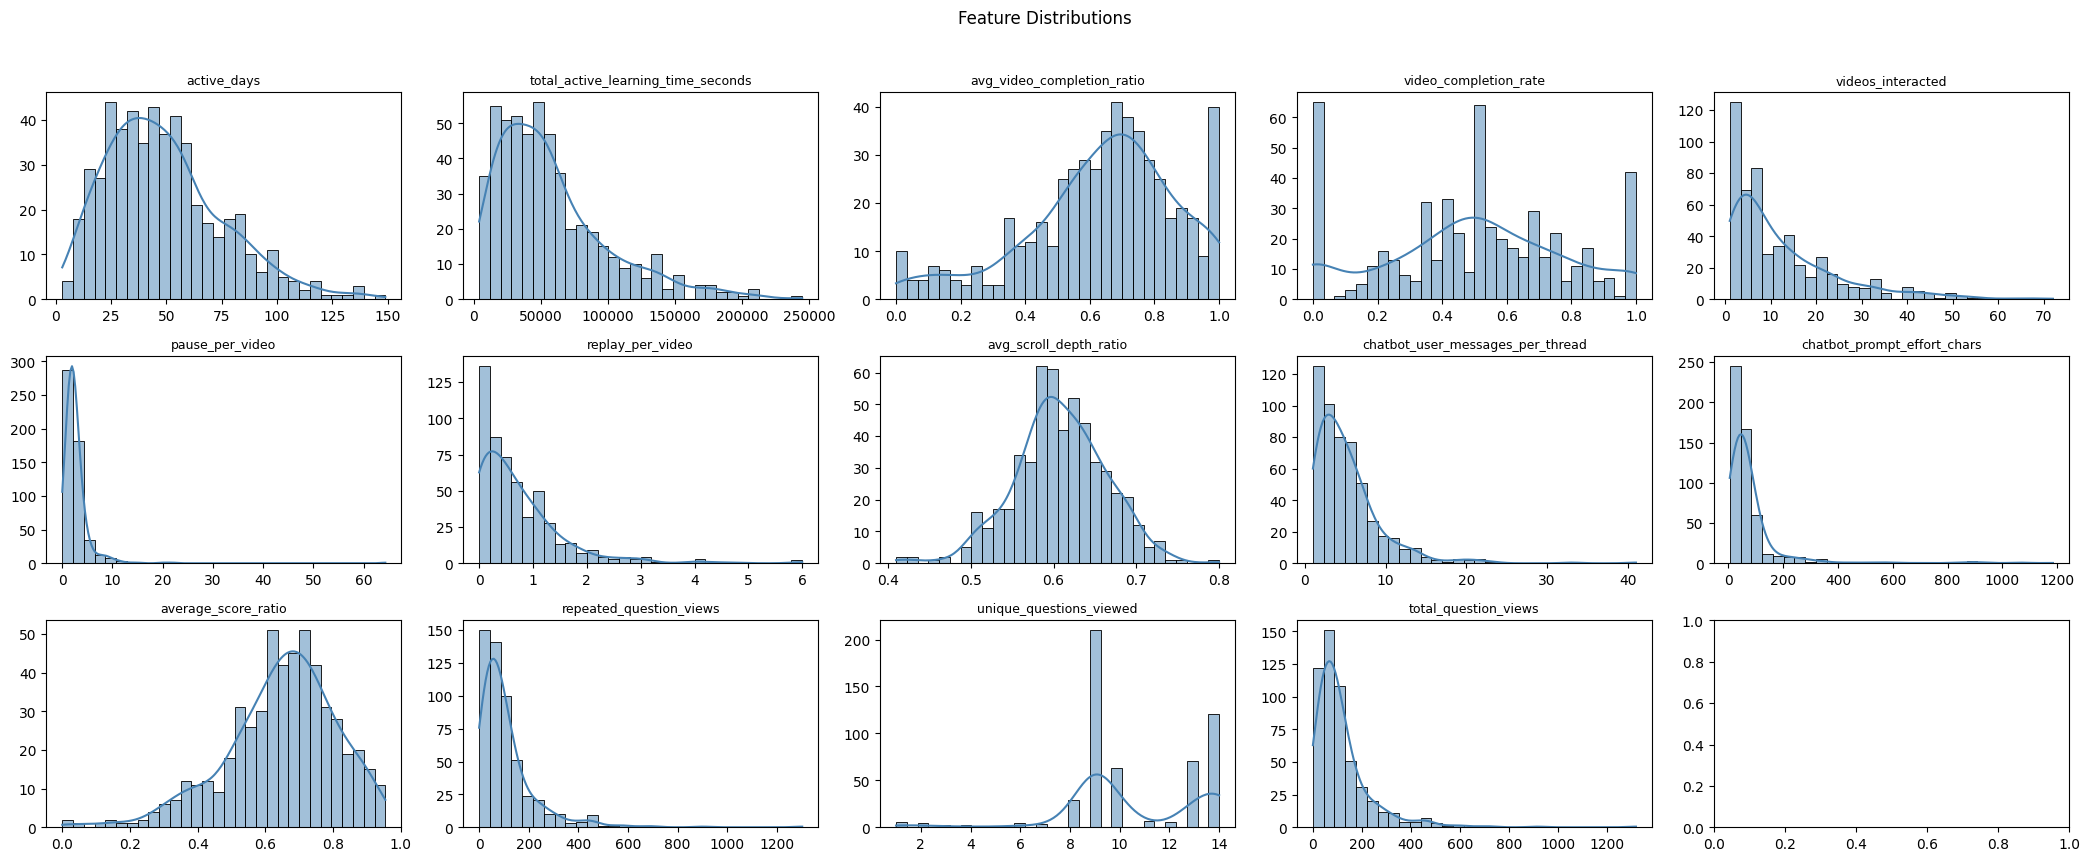

In [13]:
max_plots = 14
hist_rows = 3
hist_cols = 5
hist_bins = 30

plot_features = [i for i in features.columns.tolist() if i != 'user_id']


fig, axes = plt.subplots(hist_rows, hist_cols, figsize=(hist_cols * 4.2, hist_rows * 2.8))
axes = axes.flatten()

for i, feature in enumerate(plot_features):
    sns.histplot(features[feature], bins=hist_bins, kde=True, color='steelblue', ax=axes[i])
    axes[i].set_title(feature, fontsize=9)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

for j in range(len(plot_features), max_plots):
    axes[j].axis('off')

plt.suptitle('Feature Distributions', y=1.02)
plt.tight_layout()
plt.show()

**Initialize results dict which stores all the clustering results, and other common functions**

In [14]:
results: dict[str, dict] = {}

In [15]:
# ── Search grid ───────────────────────────────────────────────────────────────
K_RANGE      = range(2, 9)
RANDOM_STATE = 42
N_INIT       = 20          # K-Means restarts per K

In [16]:
def grid_search(X: np.ndarray) -> dict:
    """
    Grid search over K.
    Picks the K that maximises the Silhouette score.
    """
    best = {"score": -np.inf, "k": None, "labels": None}

    for k in K_RANGE:
        try:
            labels = KMeans(
                n_clusters=k,
                n_init=N_INIT,
                random_state=RANDOM_STATE,
            ).fit_predict(X)

            if len(np.unique(labels)) < 2:      # degenerate — skip
                continue

            score = silhouette_score(X, labels)
            if score > best["score"]:
                best.update(
                    score=score,
                    k=k,
                    labels=labels.copy(),
                )

        except Exception:
            continue

    return best


# ── Per-dimension runner ──────────────────────────────────────────────────────

def cluster_dimension(name: str, feature_cols: list[str], df: pd.DataFrame) -> dict:
    print(f"\n{'─' * 58}")
    print(f"  Dimension : {name}")
    print(f"  Features  : {feature_cols}")
    print(f"{'─' * 58}")

    valid_mask = df[feature_cols].notna().any(axis=1)
    n_dropped  = (~valid_mask).sum()
    if n_dropped:
        print(f"  ⚠  {n_dropped} students dropped (all features NaN).")

    X = preprocess(df[valid_mask], feature_cols)

    best = grid_search(X)

    if best["k"] is None:
        print("  ✗  No valid clustering found.")
    else:
        print(f"  Best K    : {best['k']}")
        print(f"  Silhouette: {best['score']:.4f}")
        for cid, cnt in pd.Series(best["labels"]).value_counts().sort_index().items():
            print(f"    Cluster {cid}: {cnt} students")

    best["valid_mask"] = valid_mask
    return best

def cluster_centres(dim_name, DIMENSIONS, results, features):
    feature_cols = DIMENSIONS[dim_name]
    res          = results[dim_name]

    # Get the preprocessed (but original-scale) data for valid students
    df_valid = features[res["valid_mask"]][feature_cols].copy()
    df_valid["cluster"] = res["labels"]

    # Compute per-cluster means on the RAW features (before scaling)
    centroids = df_valid.groupby("cluster")[feature_cols].mean()
    
    print(f"\n--- Centroids for dimension: {dim_name} ----")
    print(centroids.round(2).to_string())

### **K-Means on Effort**
We choose K = 2 since it maximizes the Silhouette score.

In [17]:
dim_name = "Effort"

DIMENSIONS = {
    "Effort": [
        "total_active_learning_time_seconds",
        "active_days",
        
    ],
}

def preprocess(df: pd.DataFrame, feature_cols: list[str]) -> np.ndarray:
    X = df[feature_cols].copy().astype(float)
    X = SimpleImputer(strategy="median").fit_transform(X)
    X = StandardScaler().fit_transform(X)
    return X

results[dim_name] = cluster_dimension(dim_name, DIMENSIONS[dim_name], features)

cluster_centres(dim_name, DIMENSIONS, results, features)


──────────────────────────────────────────────────────────
  Dimension : Effort
  Features  : ['total_active_learning_time_seconds', 'active_days']
──────────────────────────────────────────────────────────
  Best K    : 2
  Silhouette: 0.5366
    Cluster 0: 379 students
    Cluster 1: 152 students

--- Centroids for dimension: Effort ----
         total_active_learning_time_seconds  active_days
cluster                                                 
0                                  37002.80        36.24
1                                 108676.88        79.89


In [18]:
EFFORT_LABELS = {0: "Low Effort", 1: "High Effort"}
res = results[dim_name]
res['labels'] = [EFFORT_LABELS[label] for label in res["labels"]]

### **K-Means on Content_Depth**
We choose K = 2 since it maximizes the Silhouette score.

In [19]:
dim_name = "Content_Depth"

DIMENSIONS = {
    "Content_Depth": [
        "avg_video_completion_ratio",
        "video_completion_rate",
        "videos_interacted",
        "pause_per_video",
        "replay_per_video",
        "avg_scroll_depth_ratio",
    ],
}

def preprocess(df: pd.DataFrame, feature_cols: list[str]) -> np.ndarray:
    """
    Impute → log1p skewed columns → winsorise → RobustScaler.

    RobustScaler (centres on median, scales by IQR) is inherently less
    sensitive to remaining extremes than StandardScaler.
    """
    X = df[feature_cols].copy().astype(float)

    # 1. Median imputation
    X = pd.DataFrame(
        SimpleImputer(strategy="median").fit_transform(X),
        columns=feature_cols,
    )

    # 2. Log1p-transform skewed features (values are non-negative by construction)
    for col in feature_cols:
        if col in ['videos_interacted', 'pause_per_video', 'replay_per_video']:  # count-based features can be zero but not negative
            X[col] = np.log1p(X[col].clip(lower=0))

    # 3. Winsorise at 1st–99th percentile (per column)
    for col in feature_cols:
        lo = X[col].quantile(0.01)
        hi = X[col].quantile(0.99)
        X[col] = X[col].clip(lower=lo, upper=hi)

    # 4. Robust scaling
    return RobustScaler().fit_transform(X)

results[dim_name] = cluster_dimension(dim_name, DIMENSIONS[dim_name], features)

cluster_centres(dim_name, DIMENSIONS, results, features)


──────────────────────────────────────────────────────────
  Dimension : Content_Depth
  Features  : ['avg_video_completion_ratio', 'video_completion_rate', 'videos_interacted', 'pause_per_video', 'replay_per_video', 'avg_scroll_depth_ratio']
──────────────────────────────────────────────────────────
  Best K    : 2
  Silhouette: 0.2605
    Cluster 0: 382 students
    Cluster 1: 149 students

--- Centroids for dimension: Content_Depth ----
         avg_video_completion_ratio  video_completion_rate  videos_interacted  pause_per_video  replay_per_video  avg_scroll_depth_ratio
cluster                                                                                                                                 
0                              0.74                   0.62              15.20              3.1              0.87                    0.61
1                              0.37                   0.17               5.03              1.6              0.33                    0.60


In [20]:
CONTENT_LABELS = {0: "Deep Engagers", 1: "Surface Browsers"}
res = results[dim_name]
res['labels'] = [CONTENT_LABELS[label] for label in res["labels"]]

### **K-Means on Practice_Review**
We choose K = 2 since it maximizes the Silhouette score.

In [21]:
dim_name = "Practice_Review"

DIMENSIONS = {
    "Practice_Review": [
        "repeated_question_views",
        "unique_questions_viewed",
        "total_question_views",
    ],
}

def preprocess(df: pd.DataFrame, feature_cols: list[str]) -> np.ndarray:
    """Median-impute then z-score all features in a dimension."""
    X = df[feature_cols].copy().astype(float)

    # 1. Median imputation
    X = pd.DataFrame(
        SimpleImputer(strategy="median").fit_transform(X),
        columns=feature_cols,
    )
    # 2. Log1p-transform skewed features (values are non-negative by construction)
    for col in feature_cols:
        if col in ['repeated_question_views', 'total_question_views']:  # count-based features can be zero but not negative
            X[col] = np.log1p(X[col].clip(lower=0))

    # 3. Winsorise at 1st–99th percentile (per column)
    for col in feature_cols:
        lo = X[col].quantile(0.01)
        hi = X[col].quantile(0.99)
        X[col] = X[col].clip(lower=lo, upper=hi)

    X = RobustScaler().fit_transform(X)
    return X

results[dim_name] = cluster_dimension(dim_name, DIMENSIONS[dim_name], features)

cluster_centres(dim_name, DIMENSIONS, results, features)


──────────────────────────────────────────────────────────
  Dimension : Practice_Review
  Features  : ['repeated_question_views', 'unique_questions_viewed', 'total_question_views']
──────────────────────────────────────────────────────────
  Best K    : 2
  Silhouette: 0.5290
    Cluster 0: 108 students
    Cluster 1: 423 students

--- Centroids for dimension: Practice_Review ----
         repeated_question_views  unique_questions_viewed  total_question_views
cluster                                                                        
0                          12.94                     8.09                 21.03
1                         134.35                    11.18                145.54


In [22]:
PRACTICE_LABELS = {0: "Light Reviewers", 1: "Deep Reviewers"}
res = results[dim_name]
res['labels'] = [PRACTICE_LABELS[label] for label in res["labels"]]

### **K-Means on Help_Seeking**
We choose K = 2 since it maximizes the Silhouette score.

In [23]:
dim_name = "Help_Seeking"

DIMENSIONS = {
    "Help_Seeking": [
        "chatbot_prompt_effort_chars",
        "chatbot_user_messages_per_thread"
    ],
}

def preprocess(df: pd.DataFrame, feature_cols: list[str]) -> np.ndarray:
    """Median-impute then z-score all features in a dimension."""
    X = df[feature_cols].copy().astype(float)

    # 1. Median imputation
    X = pd.DataFrame(
        SimpleImputer(strategy="median").fit_transform(X),
        columns=feature_cols,
    )
    # 2. Log1p-transform skewed features (values are non-negative by construction)
    for col in feature_cols:
        if col in ['chatbot_prompt_effort_chars', 'chatbot_user_messages_per_thread']:  # count-based features can be zero but not negative
            X[col] = np.log1p(X[col].clip(lower=0))

    # 3. Winsorise at 1st–99th percentile (per column)
    for col in feature_cols:
        lo = X[col].quantile(0.01)
        hi = X[col].quantile(0.99)
        X[col] = X[col].clip(lower=lo, upper=hi)

    X = RobustScaler().fit_transform(X)
    return X

results[dim_name] = cluster_dimension(dim_name, DIMENSIONS[dim_name], features)

cluster_centres(dim_name, DIMENSIONS, results, features)


──────────────────────────────────────────────────────────
  Dimension : Help_Seeking
  Features  : ['chatbot_prompt_effort_chars', 'chatbot_user_messages_per_thread']
──────────────────────────────────────────────────────────
  Best K    : 2
  Silhouette: 0.3794
    Cluster 0: 147 students
    Cluster 1: 384 students

--- Centroids for dimension: Help_Seeking ----
         chatbot_prompt_effort_chars  chatbot_user_messages_per_thread
cluster                                                               
0                             197.54                              4.18
1                              39.88                              5.68


In [24]:
HELP_LABELS = {0: "Deliberate Askers", 1: "Passive Chatters"}
res = results[dim_name]
res['labels'] = [HELP_LABELS[label] for label in res["labels"]]

## **Step 2: K-Modes on Profiles**

### Prepare labels_df 
Contains one row per student one column per Dimension {Effort, Content Depth, Practice Review, Help Seeking}

In [25]:
# ── Assemble label DataFrame (input to K-Modes) ───────────────────────────────
labels_df = features[["user_id"]].copy().reset_index(drop=True)

for dim_name, res in results.items():
    col = f"label_{dim_name}"
    labels_df[col] = ""
    if res["labels"] is not None:
        valid_idx = labels_df.index[res["valid_mask"].values]
        labels_df.loc[valid_idx, col] = res["labels"]

print("\n" + "═" * 58)
print("  Label DataFrame — ready for K-Modes")
print("═" * 58)
print(labels_df.head(10).to_string(index=False))
print(f"\n  Shape : {labels_df.shape}")
print(f"  NaNs  :\n{labels_df.isna().sum().to_string()}")


══════════════════════════════════════════════════════════
  Label DataFrame — ready for K-Modes
══════════════════════════════════════════════════════════
 user_id label_Effort label_Content_Depth label_Practice_Review label_Help_Seeking
     127   Low Effort       Deep Engagers        Deep Reviewers  Deliberate Askers
     525   Low Effort    Surface Browsers        Deep Reviewers  Deliberate Askers
     564   Low Effort    Surface Browsers        Deep Reviewers   Passive Chatters
     568   Low Effort    Surface Browsers        Deep Reviewers   Passive Chatters
     569   Low Effort       Deep Engagers        Deep Reviewers   Passive Chatters
     572   Low Effort    Surface Browsers        Deep Reviewers  Deliberate Askers
     574  High Effort    Surface Browsers        Deep Reviewers   Passive Chatters
     575  High Effort       Deep Engagers        Deep Reviewers  Deliberate Askers
     577   Low Effort    Surface Browsers       Light Reviewers   Passive Chatters
     584   Lo

In [26]:
labels_df.head()

,user_id,label_Effort,label_Content_Depth,label_Practice_Review,label_Help_Seeking
0,127,Low Effort,Deep Engagers,Deep Reviewers,Deliberate Askers
1,525,Low Effort,Surface Browsers,Deep Reviewers,Deliberate Askers
2,564,Low Effort,Surface Browsers,Deep Reviewers,Passive Chatters
3,568,Low Effort,Surface Browsers,Deep Reviewers,Passive Chatters
4,569,Low Effort,Deep Engagers,Deep Reviewers,Passive Chatters


### **Check if average_score_ratio is normally distributed using Shapiro-Wilk Test**

In [27]:
score_col = 'average_score_ratio'
scores = features[score_col].dropna()
stat, p = stats.shapiro(scores)

print(f"Shapiro-Wilk Test on '{score_col}'")
print(f"  W = {stat:.4f}")
print(f"  p = {p:.4e}")

if p < 0.05:
    print("  → Not normally distributed (p < 0.05). Use non-parametric tests.")
else:
    print("  → Normally distributed (p ≥ 0.05). Parametric tests are appropriate.")

Shapiro-Wilk Test on 'average_score_ratio'
  W = 0.9674
  p = 1.7942e-09
  → Not normally distributed (p < 0.05). Use non-parametric tests.


### **K-Modes Clustering**
We choose K = 8 since it maximizes the Hamming-distance Silhouette score.

In [28]:
"""
K-Modes Clustering + Profile Scoring via average_score_ratio
=============================================================
Following Mejia-Domenzain et al., average_score_ratio is held out as the
outcome variable — not used during clustering. After profiling, we compute mean average_score_ratio per profile

Assumes in scope:
  - labels_df  : output of spectral clustering (user_id + label_* columns)
  - features   : original feature DataFrame containing user_id + average_score_ratio
"""

# ── 1. Prepare label matrix ───────────────────────────────────────────────────

label_cols  = [c for c in labels_df.columns if c.startswith("label_")]
valid_cols  = [c for c in label_cols if labels_df[c].notna().any()]
dropped     = set(label_cols) - set(valid_cols)
if dropped:
    print(f"⚠  Dropped all-NaN dimension(s): {dropped}")

df_km = labels_df[["user_id"] + valid_cols].dropna(subset=valid_cols).copy()

X_cat = df_km[valid_cols].values
print(f"   Students : {len(df_km)}   |   Dimensions : {len(valid_cols)}\n")


# ── 2. Hamming-distance Silhouette ────────────────────────────────────────────

def hamming_silhouette(X: np.ndarray, labels: np.ndarray) -> float:
    X_enc = np.zeros_like(X, dtype=float)
    for j in range(X.shape[1]):
        le = LabelEncoder()
        X_enc[:, j] = le.fit_transform(X[:, j])
    return silhouette_score(X_enc, labels, metric="hamming")


# ── 3. Grid-search K ─────────────────────────────────────────────────────────

K_RANGE      = range(2, 9)
N_INIT       = 10
RANDOM_STATE = 42

print("  K   Silhouette   Cost")
print("  " + "─" * 26)

search_results = []
for k in K_RANGE:
    km     = KModes(n_clusters=k, init="Huang", n_init=N_INIT,
                    random_state=RANDOM_STATE, verbose=0)
    lbls   = km.fit_predict(X_cat)
    if len(np.unique(lbls)) < 2:
        continue
    sil = hamming_silhouette(X_cat, lbls)
    search_results.append({"k": k, "silhouette": sil, "cost": km.cost_,
                            "labels": lbls.copy(), "model": km})
    print(f"  {k}   {sil:>9.4f}   {km.cost_:.1f}")

best = max(search_results, key=lambda r: r["silhouette"])
print(f"\n  ✔  Best K = {best['k']}  (Silhouette = {best['silhouette']:.4f})\n")

df_km["profile"] = best["labels"]


# ── 4. Merge average_score_ratio ──────────────────────────────────────────────

df_scored = df_km.merge(
    features[["user_id", score_col]].dropna(subset=[score_col]),
    on="user_id",
    how="inner",
)

   Students : 531   |   Dimensions : 4

  K   Silhouette   Cost
  ──────────────────────────
  2      0.4880   404.0
  3      0.5532   280.0
  4      0.5702   221.0
  5      0.6010   181.0
  6      0.6640   140.0
  7      0.7761   82.0
  8      0.8125   63.0

  ✔  Best K = 8  (Silhouette = 0.8125)



### Per-profile score statistics table

In [29]:
# ── 5. Per-profile score statistics ───────────────────────────────────────────

agg = (
    df_scored.groupby("profile")[score_col]
    .agg(Number_of_Students="count", Mean_Score="mean", Std_Score="std")
    .round(4)
    .sort_values("Mean_Score", ascending=False)
)

# Rank profiles by median score (1 = best)
agg["Score_Rank"] = range(1, len(agg) + 1)

# Append dimension mode for each profile
for col in valid_cols:
    dim_name = col.replace("label_", "")
    agg[dim_name] = [
        df_km.loc[df_km["profile"] == pid, col].mode()[0]
        for pid in agg.index
    ]

print("═" * 80)
print("  Profile Score Summary  (sorted by mean average_score_ratio, best first)")
print("═" * 80)
print(agg.to_string())

════════════════════════════════════════════════════════════════════════════════
  Profile Score Summary  (sorted by mean average_score_ratio, best first)
════════════════════════════════════════════════════════════════════════════════
         Number_of_Students  Mean_Score  Std_Score  Score_Rank       Effort     Content_Depth  Practice_Review       Help_Seeking
profile                                                                                                                          
4                        55      0.6999     0.1393           1  High Effort     Deep Engagers   Deep Reviewers  Deliberate Askers
5                        40      0.6903     0.1397           2   Low Effort     Deep Engagers   Deep Reviewers  Deliberate Askers
2                        74      0.6784     0.1530           3  High Effort     Deep Engagers   Deep Reviewers   Passive Chatters
7                       156      0.6562     0.1441           4   Low Effort     Deep Engagers   Deep Reviewers   P

### **Run a Kruskal-Wallis test (non-parametric, robust to unequal variance) to check whether profiles differ significantly in score.**

In [30]:
groups = [
    df_scored.loc[df_scored["profile"] == pid, score_col].values
    for pid in sorted(df_scored["profile"].unique())
]
kw_stat, kw_p = stats.kruskal(*groups)

print(f"\n  Kruskal-Wallis  H = {kw_stat:.3f},  p = {kw_p:.4e}")
if kw_p < 0.05:
    print("  → Profiles differ significantly in average_score_ratio (p < 0.05).")
else:
    print("  → No significant overall difference (p ≥ 0.05).\n")


  Kruskal-Wallis  H = 18.963,  p = 8.3037e-03
  → Profiles differ significantly in average_score_ratio (p < 0.05).


### Profile performance plot

Distribution of held-out `average_score_ratio` across the eight learner profiles, ranked best to worst by mean and coloured by performance tier (Figure in the report). Reuses `agg` (profiles sorted best-first), `df_scored`, `score_col`, and the `kw_stat`/`kw_p` from the Kruskal–Wallis test above.

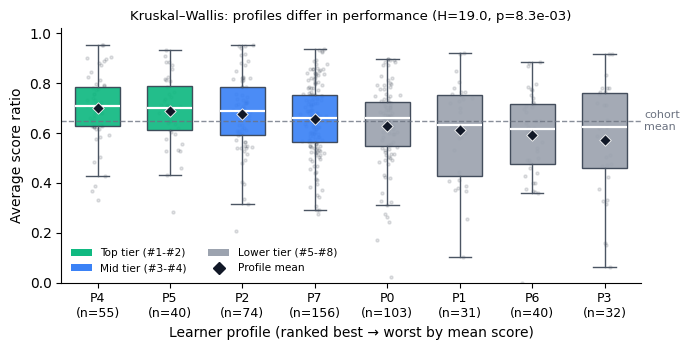

In [31]:
# ── Profile performance figure ──
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

C_TOP, C_MID, C_LOW = '#10B981', '#3B82F6', '#9CA3AF'   # top / mid / lower tier
tier_color = lambda rank: C_TOP if rank <= 2 else (C_MID if rank <= 4 else C_LOW)

order = list(agg.index)                                  # profile ids, best -> worst
data  = [df_scored.loc[df_scored['profile'] == pid, score_col].values for pid in order]
pos   = range(1, len(order) + 1)

fig, ax = plt.subplots(figsize=(7.0, 3.6))
bp = ax.boxplot(data, positions=pos, widths=0.62, patch_artist=True, showfliers=False,
                medianprops=dict(color='white', lw=1.6),
                whiskerprops=dict(color='#4B5563'), capprops=dict(color='#4B5563'))
for i, box in enumerate(bp['boxes']):
    box.set(facecolor=tier_color(i + 1), edgecolor='#374151', alpha=0.92, lw=1.0)

for i, pid in enumerate(order):
    vals = df_scored.loc[df_scored['profile'] == pid, score_col].values
    ax.scatter(np.random.normal(i + 1, 0.07, len(vals)), vals, s=5, color='#1F2937', alpha=0.12, zorder=1)
    ax.scatter(i + 1, vals.mean(), marker='D', s=34, color='#111827', zorder=4, edgecolor='white', lw=0.6)

ax.set_xticks(list(pos))
ax.set_xticklabels([f"P{pid}\n(n={int(agg.loc[pid, 'Number_of_Students'])})" for pid in order], fontsize=9)
ax.set_ylabel('Average score ratio')
ax.set_xlabel('Learner profile (ranked best → worst by mean score)')
ax.set_ylim(0.0, 1.02)
ax.axhline(df_scored[score_col].mean(), ls='--', lw=1, color='#6B7280', alpha=0.8)
ax.text(len(order) + 0.55, df_scored[score_col].mean(), 'cohort\nmean', fontsize=8, color='#6B7280', va='center')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)

leg = [Patch(facecolor=C_TOP, label='Top tier (#1-#2)'),
       Patch(facecolor=C_MID, label='Mid tier (#3-#4)'),
       Patch(facecolor=C_LOW, label='Lower tier (#5-#8)'),
       plt.Line2D([], [], marker='D', color='#111827', ls='', ms=6, label='Profile mean')]
ax.legend(handles=leg, fontsize=7.6, loc='lower left', frameon=False, ncol=2)
ax.set_title(f'Kruskal–Wallis: profiles differ in performance (H={kw_stat:.1f}, p={kw_p:.1e})', fontsize=9.5)
fig.tight_layout()
fig.savefig('M7_MLBD_Final_Report/rq1_profiles.png', dpi=1000, bbox_inches='tight')
plt.show()


### Do higher-performing profiles show lower score dispersion?

Beyond the *level* difference confirmed by Kruskal-Wallis, we test whether the **upper-half profiles** (top performers by mean score) are also **more consistent** — i.e. have a lower standard deviation in `average_score_ratio` — than the **lower-half profiles**.

This is a question about *scale*, not central tendency, so we use a homogeneity-of-variance test. Because scores are non-normal (Shapiro-Wilk \(p<0.05\)), we use the **Fligner-Killeen** test — the scale test most robust to departures from normality. It tests \(H_0\): equal variances.

To isolate genuine *within-profile* consistency rather than differences in profile means, we first **center each student by their own profile median** (removing between-profile median gaps), then compare the spread of the two pooled groups. Since the hypothesis is directional (upper < lower), we read the direction off the group standard deviations and report the one-sided \(p\) (two-sided \(p/2\)) when the direction holds.

The test supports the difference (one-sided $p=6.0\times10^{-3}$), hence higher-performing profiles do show lower score dispersion.

In [32]:
# ── Upper vs lower profiles: within-profile score-dispersion comparison ─────
# Profiles ranked by mean score live in `agg` (sorted best-first, Score_Rank=1 is best).
ranked_profiles = list(agg.index)                  # profile ids, best -> worst
n_half          = len(ranked_profiles) // 2        # 8 profiles -> 4 vs 4

upper_profiles = ranked_profiles[:n_half]          # higher-performing
lower_profiles = ranked_profiles[-n_half:]         # lower-performing
middle         = ranked_profiles[n_half:len(ranked_profiles) - n_half]  # dropped if odd count

print(f"Total profiles: {len(ranked_profiles)}  ->  upper {len(upper_profiles)} vs lower {len(lower_profiles)}"
      + (f"  (excluded middle profile(s): {middle})" if middle else ""))
print(f"  Upper (high-performing) profile ids: {upper_profiles}")
print(f"  Lower (low-performing)  profile ids: {lower_profiles}\n")

# Center each student by their own profile median so between-profile mean gaps
# don't inflate spread -> the test reflects genuine within-profile dispersion.
centered = (df_scored[score_col]
            - df_scored.groupby("profile")[score_col].transform("median"))
upper_c = centered[df_scored["profile"].isin(upper_profiles)].values
lower_c = centered[df_scored["profile"].isin(lower_profiles)].values

print(f"  Upper group: n = {len(upper_c):4d},  within-profile std = {upper_c.std(ddof=1):.4f}")
print(f"  Lower group: n = {len(lower_c):4d},  within-profile std = {lower_c.std(ddof=1):.4f}")

direction_ok = upper_c.std(ddof=1) < lower_c.std(ddof=1)
print(f"  Observed direction (upper std < lower std): {direction_ok}\n")

fl_stat, fl_p = stats.fligner(upper_c, lower_c)            # Fligner-Killeen
p_one   = fl_p / 2 if direction_ok else 1 - fl_p / 2       # one-sided p for H1: upper variance < lower variance
verdict = "supported" if (direction_ok and p_one < 0.05) else "not supported"
print(f"  Fligner-Killeen   stat = {fl_stat:.4f}   two-sided p = {fl_p:.4e}   "
      f"one-sided p = {p_one:.4e}   -> {verdict}")

if verdict == 'supported':
    print("\nHence, Upper-half profiles are more consistent than the Lower-half profiles.")
else:
    print("\nWe cannot claim Upper-half profiles are more consistent than the Lower-half profiles.")

Total profiles: 8  ->  upper 4 vs lower 4
  Upper (high-performing) profile ids: [4, 5, 2, 7]
  Lower (low-performing)  profile ids: [0, 1, 6, 3]

  Upper group: n =  325,  within-profile std = 0.1442
  Lower group: n =  206,  within-profile std = 0.1811
  Observed direction (upper std < lower std): True

  Fligner-Killeen   stat = 6.3091   two-sided p = 1.2012e-02   one-sided p = 6.0061e-03   -> supported

Hence, Upper-half profiles are more consistent than the Lower-half profiles.


### Justifying K-Means: a quick stability check / baseline clustering

We justify K-Means empirically on the **531 profiled students** (`df_scored`), the same cohort used for the final profiles:

* **Stability** — refit K-Means on 100 random 80% subsamples and compare each to the full-cohort labels (Adjusted Rand Index). We get High ARI which denotes the binary labels are reproducible, not an artefact of one fit.
* **Baseline** — compare the K-Means silhouette against a random 2-way labelling. We get K-Means silhoutte score far above chance which represents genuine structure.


In [33]:
# ── Stability check + baseline clustering on the 531 profiled students ──
import numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Same cohort as the final profiles: the students in df_scored.
_cohort = features[features['user_id'].isin(df_scored['user_id'])].reset_index(drop=True)
print(f'Stability cohort: {len(_cohort)} students\n')

# Per-dimension feature sets + preprocessing (mirrors the clustering pipeline).
_DIMS = {
    'Effort':          dict(cols=['total_active_learning_time_seconds','active_days'], log=[], scaler='std'),
    'Content Depth':   dict(cols=['avg_video_completion_ratio','video_completion_rate','videos_interacted','pause_per_video','replay_per_video','avg_scroll_depth_ratio'], log=['videos_interacted','pause_per_video','replay_per_video'], scaler='robust'),
    'Practice Review': dict(cols=['repeated_question_views','unique_questions_viewed','total_question_views'], log=['repeated_question_views','total_question_views'], scaler='robust'),
    'Help Seeking':    dict(cols=['chatbot_prompt_effort_chars','chatbot_user_messages_per_thread'], log=['chatbot_prompt_effort_chars','chatbot_user_messages_per_thread'], scaler='robust'),
}

def _prep(d, cfg):
    cols = cfg['cols']
    X = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(d[cols].astype(float)), columns=cols)
    for c in cfg['log']:
        X[c] = np.log1p(X[c].clip(lower=0))
    for c in cols:
        lo, hi = X[c].quantile(0.01), X[c].quantile(0.99)
        X[c] = X[c].clip(lo, hi)
    return (StandardScaler() if cfg['scaler']=='std' else RobustScaler()).fit_transform(X)

_rng = np.random.default_rng(42)
_B, _FRAC = 100, 0.8
print(f"{'Dimension':16}{'bootstrap ARI':>20}{'KM sil':>9}{'random sil':>12}")
print('-'*57)
for name, cfg in _DIMS.items():
    X = _prep(_cohort, cfg); n = X.shape[0]
    ref = KMeans(n_clusters=2, n_init=20, random_state=42).fit(X).labels_     # reference partition
    aris = []
    for _ in range(_B):                                                       # bootstrap stability
        idx = _rng.choice(n, size=int(_FRAC*n), replace=False)
        lab = KMeans(n_clusters=2, n_init=5, random_state=int(_rng.integers(1e6))).fit_predict(X[idx])
        aris.append(adjusted_rand_score(ref[idx], lab))
    aris = np.array(aris)
    rand_sil = np.mean([silhouette_score(X, _rng.integers(0, 2, n)) for _ in range(20)])  # baseline
    print(f'{name:16}{aris.mean():>14.3f} \u00b1 {aris.std():.3f}{silhouette_score(X, ref):>9.3f}{rand_sil:>12.3f}')

# High bootstrap ARI (labels reproducible under resampling) + silhouette far above the random
# baseline justify K-Means as the per-dimension clusterer.


Stability cohort: 531 students

Dimension              bootstrap ARI   KM sil  random sil
---------------------------------------------------------
Effort                   0.964 ± 0.030    0.534       0.000
Content Depth            0.928 ± 0.062    0.260       0.000
Practice Review          0.901 ± 0.061    0.529       0.000
Help Seeking             0.915 ± 0.084    0.379      -0.000


We visualise the per-dimension K-Means silhouette against the random-label baseline, with the bootstrap ARI annotated above each bar (Figure in the report). Reuses `_DIMS`, `_prep`, and `_cohort` from the stability check above.

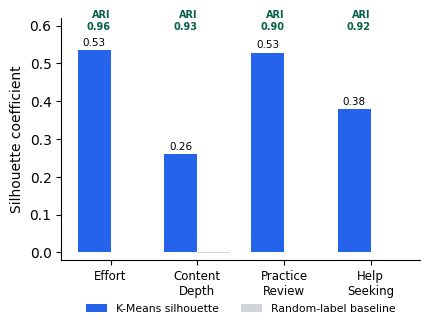

In [34]:
# ── Cluster validity & bootstrap stability figure ──
import numpy as np
import matplotlib.pyplot as plt

# Canonical bootstrap ARI values from the stability check above (mean over 100 subsamples).
ARI = {'Effort': 0.96, 'Content Depth': 0.93, 'Practice Review': 0.90, 'Help Seeking': 0.92}

dims  = list(_DIMS.keys())
km_sil, rand_sil = [], []
for name in dims:
    X = _prep(_cohort, _DIMS[name])
    ref = KMeans(n_clusters=2, n_init=20, random_state=42).fit(X).labels_
    km_sil.append(silhouette_score(X, ref))
    rand_sil.append(np.mean([silhouette_score(X, _rng.integers(0, 2, X.shape[0])) for _ in range(20)]))

disp = ['Effort', 'Content\nDepth', 'Practice\nReview', 'Help\nSeeking']
x, w = np.arange(len(dims)), 0.38

fig, ax = plt.subplots(figsize=(4.4, 3.4))
ax.bar(x - w/2, km_sil,   w, color='#2563EB', label='K-Means silhouette')
ax.bar(x + w/2, rand_sil, w, color='#D1D5DB', label='Random-label baseline')
ax.set_xticks(x); ax.set_xticklabels(disp, fontsize=8.5)
ax.set_ylabel('Silhouette coefficient'); ax.set_ylim(-0.02, 0.62)
for xi, v in zip(x - w/2, km_sil):
    ax.text(xi, v + 0.012, f'{v:.2f}', ha='center', fontsize=7.5)
for xi, name in zip(x, dims):
    ax.text(xi, 0.59, f'ARI\n{ARI[name]:.2f}', ha='right', fontsize=7.0,
            color='#065F46', fontweight='bold')
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
#ax.set_title('Cluster validity & bootstrap stability', fontsize=9.5)
ax.legend(fontsize=7.8, loc='upper center', frameon=False,
          bbox_to_anchor=(0.5, -0.14), ncol=2)
fig.tight_layout()
fig.savefig('M7_MLBD_Final_Report/rq1_validation.png', dpi=1000, bbox_inches='tight')
plt.show()


## RQ2 — Phase 1: Linear Models (Hierarchical OLS)

Before the non-linear ensembles, we fit a **two-level hierarchical Ordinary Least Squares (OLS) regression** on the continuous outcome `average_score_ratio`. Linear regression is used at this stage precisely because its coefficients are directly interpretable as marginal effects, answering the *"which behaviours, and in what direction"* part of RQ2 transparently.

- **Level 1 — Dimension level.** Regress performance on all four binary cluster-dimension labels (`effort_label`, `contentdepth_label`, `practicereview_label`, `helpseeking_label`) simultaneously, so each coefficient gives that dimension's direction and relative importance while controlling for the others.
- **Level 2 — Feature level.** Within each dimension, regress performance on the raw behavioural features to isolate each feature's independent contribution.

Before fitting, we guard against multicollinearity with the **Variance Inflation Factor (VIF, threshold 5)** and iterative removal, alongside pairwise-correlation checks. Model fit is reported via $R^2$ / adjusted $R^2$ and the overall $F$-test, individual predictors are judged by their $t$-statistics and $p$-values, and **5-fold cross-validated $R^2$** is reported to gauge out-of-sample generalisation.

### Setup — build the regression frame & binary dimension labels

The four categorical dimension labels are converted to binary indicators, where 1 marks the behaviourally "positive" cluster for each dimension:

| Dimension | Positive (=1) cluster |
|---|---|
| Effort | High Effort |
| Content Depth | Deep Engagers |
| Practice Review | Deep Reviewers |
| Help Seeking | Deliberate Askers |

In [35]:
# ── RQ2 Phase 1 setup: imports + regression frame ───────────────────────────
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

import warnings
warnings.filterwarnings("ignore")

VIF_THRESHOLD = 5.0
SIG_THRESHOLD = 0.05
CV_FOLDS      = 5
RANDOM_STATE  = 42
kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Map each dimension's label column -> (positive cluster string, binary col name)
DIM_LABEL_SPEC = {
    "Effort":         ("label_Effort",         "High Effort",       "effort_label"),
    "Content_Depth":  ("label_Content_Depth",  "Deep Engagers",     "contentdepth_label"),
    "Practice_Review":("label_Practice_Review","Deep Reviewers",    "practicereview_label"),
    "Help_Seeking":   ("label_Help_Seeking",   "Deliberate Askers", "helpseeking_label"),
}

# Build the regression frame: features + binary dimension labels
reg = features.merge(labels_df, on="user_id", how="left")

for dim, (str_col, positive, bin_col) in DIM_LABEL_SPEC.items():
    reg[bin_col] = (reg[str_col] == positive).astype(float)
    # treat missing / empty cluster assignments as NaN
    reg.loc[reg[str_col].isna() | (reg[str_col].astype(str) == ""), bin_col] = np.nan

dim_predictors = ["effort_label", "contentdepth_label",
                  "practicereview_label", "helpseeking_label"]

print(f"Regression frame shape: {reg.shape}")
print("Binary dimension-label counts (positive = 1):")
print(reg[dim_predictors].sum().astype(int).to_string())


Regression frame shape: (531, 23)
Binary dimension-label counts (positive = 1):
effort_label            152
contentdepth_label      382
practicereview_label    423
helpseeking_label       147


### Level 1 — Dimension-level OLS

Regress `average_score_ratio` on the four binary dimension labels simultaneously, with VIF and pairwise-correlation multicollinearity checks and 5-fold cross-validated $R^2$.

In [36]:
# ── LEVEL 1 — Dimension-level OLS ───────────────────────────────────────────
df1 = reg[["average_score_ratio"] + dim_predictors].dropna()
print(f"N = {len(df1)}\n")

# Variance Inflation Factors (should all be < 5)
print("VIF (multicollinearity check, threshold = 5):")
X1_raw = df1[dim_predictors].values
for i, col in enumerate(dim_predictors):
    print(f"  {col:24s}  VIF = {variance_inflation_factor(X1_raw, i):.2f}")

print("All VIF < 5 — no multicollinearity issues.")

# Pairwise correlation among predictors
print("\nPairwise correlation among predictors:")
print(df1[dim_predictors].corr().round(3).to_string())

# OLS fit
X1 = sm.add_constant(df1[dim_predictors])
y1 = df1["average_score_ratio"]
model1 = sm.OLS(y1, X1).fit()
print("\n" + model1.summary().as_text())

# 5-fold cross-validated R2 (out-of-sample)
cv1 = cross_val_score(LinearRegression(), df1[dim_predictors].values,
                      y1.values, cv=kf, scoring="r2")
print(f"\n5-Fold CV R2 (per fold): {np.round(cv1, 4)}")
print(f"Mean CV R2  : {cv1.mean():.4f}")
print(f"Std  CV R2  : {cv1.std():.4f}")
print(f"In-sample R2: {model1.rsquared:.4f}")

# Which dimensions are significant at p < 0.05?
pvals_l1 = model1.pvalues[dim_predictors]
significant_dims = [d for d, (_, _, bc) in DIM_LABEL_SPEC.items()
                    if pvals_l1[bc] < SIG_THRESHOLD]
print(f"\nSignificant dimensions (p < {SIG_THRESHOLD}): "
      f"{significant_dims if significant_dims else 'none'}")


N = 531

VIF (multicollinearity check, threshold = 5):
  effort_label              VIF = 1.54
  contentdepth_label        VIF = 2.75
  practicereview_label      VIF = 2.84
  helpseeking_label         VIF = 1.36
All VIF < 5 — no multicollinearity issues.

Pairwise correlation among predictors:
                      effort_label  contentdepth_label  practicereview_label  helpseeking_label
effort_label                 1.000               0.164                 0.206              0.167
contentdepth_label           0.164               1.000                 0.111              0.059
practicereview_label         0.206               0.111                 1.000             -0.012
helpseeking_label            0.167               0.059                -0.012              1.000

                             OLS Regression Results                            
Dep. Variable:     average_score_ratio   R-squared:                       0.046
Model:                             OLS   Adj. R-squared:         

### Level 2 — Feature-level OLS (per dimension)

For each dimension, regress `average_score_ratio` on its raw behavioural features to isolate each feature's independent contribution. Highly collinear features are removed iteratively (VIF > 5), and 5-fold cross-validated $R^2$ is reported alongside the in-sample fit. Level 2 is run for **all** dimensions for completeness.

In [37]:
# ── LEVEL 2 — Feature-level OLS (per dimension) ─────────────────────────────
DIM_FEATURES = {
    "Effort":          ["active_days", "total_active_learning_time_seconds"],
    "Content_Depth":   ["avg_video_completion_ratio", "video_completion_rate",
                        "videos_interacted", "pause_per_video", "replay_per_video",
                        "avg_scroll_depth_ratio"],
    "Practice_Review": ["repeated_question_views", "unique_questions_viewed",
                        "total_question_views"],
    "Help_Seeking":    ["chatbot_user_messages_per_thread", "chatbot_prompt_effort_chars"],
}

def vif_prune(df, feat_cols, threshold=VIF_THRESHOLD):
    """Iteratively drop the highest-VIF feature above threshold."""
    remaining, removed = feat_cols[:], []
    while len(remaining) >= 2:
        Xv = df[remaining].values
        vifs = {remaining[i]: variance_inflation_factor(Xv, i)
                for i in range(len(remaining))}
        worst = max(vifs, key=vifs.get)
        if vifs[worst] > threshold:
            print(f"    Removing {worst} (VIF = {vifs[worst]:.2f})")
            removed.append(worst); remaining.remove(worst)
        else:
            break
    return remaining, removed

l2_rows = []
for dim_name, feat_cols in DIM_FEATURES.items():
    marker = "*** SIGNIFICANT in Level 1 ***" if dim_name in significant_dims else "(not significant in Level 1)"
    print("\n" + "=" * 70)
    print(f"  Dimension: {dim_name}   {marker}")
    print("=" * 70)

    df2 = reg[["average_score_ratio"] + feat_cols].dropna()
    print(f"  N = {len(df2)}")
    if len(df2) < 10:
        print("  Skipping — too few observations.")
        continue

    print("\n  Pairwise correlation (features):")
    print(df2[feat_cols].corr().round(3).to_string())

    print("\n  VIF pruning:")
    remaining, removed = vif_prune(df2, feat_cols)
    print(f"  Retained: {remaining}")
    if removed:
        print(f"  Removed : {removed}")
    if not remaining:
        print("  No features left after VIF pruning."); continue

    X2 = sm.add_constant(df2[remaining])
    y2 = df2["average_score_ratio"]
    model2 = sm.OLS(y2, X2).fit()
    print("\n" + model2.summary().as_text())

    cv2 = cross_val_score(LinearRegression(), df2[remaining].values,
                          y2.values, cv=kf, scoring="r2")
    print(f"\n  5-Fold CV R2 (per fold): {np.round(cv2, 4)}")
    print(f"  Mean CV R2  : {cv2.mean():.4f}")
    print(f"  Std  CV R2  : {cv2.std():.4f}")
    print(f"  In-sample R2: {model2.rsquared:.4f}")

    l2_rows.append({
        "Dimension":         dim_name,
        "N":                 len(df2),
        "Retained features": ", ".join(remaining),
        "In-sample R2":      round(model2.rsquared, 4),
        "Mean CV R2":        round(cv2.mean(), 4),
        "Std CV R2":         round(cv2.std(), 4),
    })

# ── Summary table ───────────────────────────────────────────────────────────
print("\n" + "=" * 70)
print("SUMMARY — Level 2 feature-level OLS")
print("=" * 70)
summary_df = pd.DataFrame(l2_rows)
print(summary_df.to_string(index=False))



  Dimension: Effort   (not significant in Level 1)
  N = 531

  Pairwise correlation (features):
                                    active_days  total_active_learning_time_seconds
active_days                               1.000                               0.752
total_active_learning_time_seconds        0.752                               1.000

  VIF pruning:
    Removing active_days (VIF = 6.60)
  Retained: ['total_active_learning_time_seconds']
  Removed : ['active_days']

                             OLS Regression Results                            
Dep. Variable:     average_score_ratio   R-squared:                       0.046
Model:                             OLS   Adj. R-squared:                  0.044
Method:                  Least Squares   F-statistic:                     25.39
Date:                 Thu, 04 Jun 2026   Prob (F-statistic):           6.43e-07
Time:                         16:55:10   Log-Likelihood:                 221.88
No. Observations:                  5

## RQ2 — Phase 2: Non-Linear Models with Post-hoc Explainability

Linear regression cannot capture feature interactions. We therefore complement it with two ensemble models analyzed via SHAP and LIME. Every model here **regresses on the continuous `average_score_ratio`** using the same **VIF-screened 10-feature** predictor set as the Phase-1 hierarchical linear regression, so the linear and non-linear analyses are directly comparable. Performance is reported as cross-validated R².

- **XGBoost (Primary)** — main non-linear model. An `XGBRegressor` predicting `average_score_ratio` under 5-fold cross-validation. Preferred because TreeSHAP can compute exact Shapley values for it efficiently, and its φ values come out directly in score-ratio units.
- **Random Forest (Supplementary)** — robustness check. If SHAP importance rankings from the RF regressor agree with those from XGBoost, our conclusions are substantially more credible.
- **SHAP (Primary Explainability Method)** — TreeSHAP decomposes each prediction into individual feature contributions. Analyzed globally (mean |φ_f|) and visually (beeswarm / bar plots), and aggregated to the dimension level.
- **LIME (Comparative Method)** — applied in regression mode to **every** one of the 531 students (following Swamy et al.) and cross-examined against SHAP on two metrics: Spearman rank-order correlation and Jensen–Shannon distance. Serves as an independent corroborating explainer rather than the primary one.


### Setup — imports, feature/target preparation

In [38]:
# Phase 2 imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.base import clone

import xgboost as xgb
import shap
import lime
import lime.lime_tabular

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42


In [39]:
# ── Build X (10 VIF-screened behavioural features) and continuous y (average_score_ratio) ──
#
# Same VIF-screened predictor set as the Phase-1 hierarchical linear regression, so the
# linear and non-linear analyses are directly comparable. Three features are dropped for
# multicollinearity:
#   • active_days                 (VIF 6.60  — collinear with total_active_learning_time_seconds)
#   • avg_video_completion_ratio  (VIF 42.84 — collinear with video_completion_rate)
#   • repeated_question_views     (VIF ∞     — perfectly collinear with total_question_views)

FEATURE_COLS = [
    # Effort  (active_days dropped)
    "total_active_learning_time_seconds",
    # Content Depth  (avg_video_completion_ratio dropped)
    "video_completion_rate",
    "videos_interacted",
    "pause_per_video",
    "replay_per_video",
    "avg_scroll_depth_ratio",
    # Help Seeking
    "chatbot_user_messages_per_thread",
    "chatbot_prompt_effort_chars",
    # Practice Review  (repeated_question_views dropped)
    "unique_questions_viewed",
    "total_question_views",
]

# Map raw feature -> dimension (used later for grouped SHAP analysis)
FEATURE_TO_DIM = {
    "total_active_learning_time_seconds":"Effort",
    "video_completion_rate":             "Content_Depth",
    "videos_interacted":                 "Content_Depth",
    "pause_per_video":                   "Content_Depth",
    "replay_per_video":                  "Content_Depth",
    "avg_scroll_depth_ratio":            "Content_Depth",
    "chatbot_user_messages_per_thread":  "Help_Seeking",
    "chatbot_prompt_effort_chars":       "Help_Seeking",
    "unique_questions_viewed":           "Practice_Review",
    "total_question_views":              "Practice_Review",
}

data = features.dropna(subset=["average_score_ratio"]).copy()

# Median-impute any residual NaNs so XGBoost / RF / SHAP run cleanly
X = data[FEATURE_COLS].astype(float)
X = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(X),
    columns=FEATURE_COLS,
    index=data.index,
)

# Continuous regression target
y = data["average_score_ratio"].values.astype(float)

# Cohort median kept only as a reference value for the at-risk verification below
median_score = data["average_score_ratio"].median()

print(f"Samples       : {X.shape[0]}")
print(f"Features      : {X.shape[1]}  (VIF-screened)")
print(f"Target (average_score_ratio): mean = {y.mean():.4f}, std = {y.std():.4f}, "
      f"min = {y.min():.4f}, max = {y.max():.4f}")
print(f"Cohort median : {median_score:.4f}")


Samples       : 531
Features      : 10  (VIF-screened)
Target (average_score_ratio): mean = 0.6488, std = 0.1631, min = 0.0000, max = 0.9545
Cohort median : 0.6656


### XGBoost (Primary) — 5-fold CV (regression on average_score_ratio, VIF-screened features)

In [40]:
# ── XGBRegressor with 5-fold CV — R² ──

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

xgb_reg = xgb.XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=10.0,
    min_child_weight=5,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

r2_scores  =  cross_val_score(xgb_reg, X, y, cv=kf, scoring="r2",                           n_jobs=-1)

print("XGBRegressor (VIF-screened) — 5-fold CV on average_score_ratio")
print(f"  R2   : {r2_scores.mean():+.4f} ± {r2_scores.std():.4f}    (per-fold: {np.round(r2_scores, 3).tolist()})")

# Out-of-fold predictions (used for the predicted-vs-actual scatter)
y_pred_oof = cross_val_predict(xgb_reg, X, y, cv=kf, n_jobs=-1)
print(f"\nAggregate out-of-fold R2  : {r2_score(y, y_pred_oof):+.4f}")

# Fit the final model on the full dataset for SHAP analysis
xgb_reg.fit(X, y)


XGBRegressor (VIF-screened) — 5-fold CV on average_score_ratio
  R2   : +0.0492 ± 0.0284    (per-fold: [0.041, 0.017, 0.061, 0.098, 0.029])

Aggregate out-of-fold R2  : +0.0543


,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.9
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_meth

In [41]:
# ── Train-set R² (in-sample) vs CV R² (out-of-sample) — overfit gap ──

y_train_pred = xgb_reg.predict(X)
print("XGBRegressor — full-data in-sample fit")
print(f"  R2   : {r2_score(y, y_train_pred):+.4f}")

print("\nPer-fold train R2 vs validation R2:")
print(f"  {'fold':>4}   {'train R2':>10}   {'val R2':>10}   {'gap':>8}")

train_r2s, val_r2s = [], []
for fold, (tr_idx, va_idx) in enumerate(kf.split(X), start=1):
    m = clone(xgb_reg).fit(X.iloc[tr_idx], y[tr_idx])
    r2_tr = r2_score(y[tr_idx], m.predict(X.iloc[tr_idx]))
    r2_va = r2_score(y[va_idx], m.predict(X.iloc[va_idx]))
    train_r2s.append(r2_tr); val_r2s.append(r2_va)
    print(f"  {fold:>4}   {r2_tr:>+10.4f}   {r2_va:>+10.4f}   {r2_tr - r2_va:>+8.4f}")

print(f"\n  mean   {np.mean(train_r2s):>+10.4f}   {np.mean(val_r2s):>+10.4f}   "
      f"{np.mean(train_r2s) - np.mean(val_r2s):>+8.4f}")

gap = np.mean(train_r2s) - np.mean(val_r2s)


XGBRegressor — full-data in-sample fit
  R2   : +0.3234

Per-fold train R2 vs validation R2:
  fold     train R2       val R2        gap
     1      +0.3580      +0.0410    +0.3170
     2      +0.3691      +0.0167    +0.3524
     3      +0.3503      +0.0607    +0.2896
     4      +0.3500      +0.0981    +0.2519
     5      +0.3635      +0.0292    +0.3343

  mean      +0.3582      +0.0492    +0.3090


### SHAP — Global & Visual Analysis

TreeSHAP decomposes each prediction into individual feature contributions:
$$\hat{y}(x) = \phi_0 + \sum_{f=1}^{F} \phi_f(x)$$

- **Global**: mean |φ_f| across all students → overall feature importance.
- **Visual**: beeswarm and bar plots showing each feature's magnitude and direction.


In [42]:
# ── TreeSHAP on XGBoost regressor — φ values in score-ratio units ──

explainer_xgb = shap.TreeExplainer(xgb_reg)
shap_values_xgb = explainer_xgb.shap_values(X)

# Global feature importance: mean |phi_f|
mean_abs_shap_xgb = np.abs(shap_values_xgb).mean(axis=0)
shap_imp_xgb = (
    pd.DataFrame({
        "feature": FEATURE_COLS,
        "dimension": [FEATURE_TO_DIM[f] for f in FEATURE_COLS],
        "mean_abs_shap": mean_abs_shap_xgb,
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)
print("XGBoost — Global SHAP importance (mean |phi_f|, score-ratio units):")
print(shap_imp_xgb.to_string(index=False))


XGBoost — Global SHAP importance (mean |phi_f|, score-ratio units):
                           feature       dimension  mean_abs_shap
total_active_learning_time_seconds          Effort       0.021693
             video_completion_rate   Content_Depth       0.013063
  chatbot_user_messages_per_thread    Help_Seeking       0.010795
           unique_questions_viewed Practice_Review       0.008942
              total_question_views Practice_Review       0.008292
                  replay_per_video   Content_Depth       0.006364
       chatbot_prompt_effort_chars    Help_Seeking       0.006211
                 videos_interacted   Content_Depth       0.005686
            avg_scroll_depth_ratio   Content_Depth       0.003575
                   pause_per_video   Content_Depth       0.002974


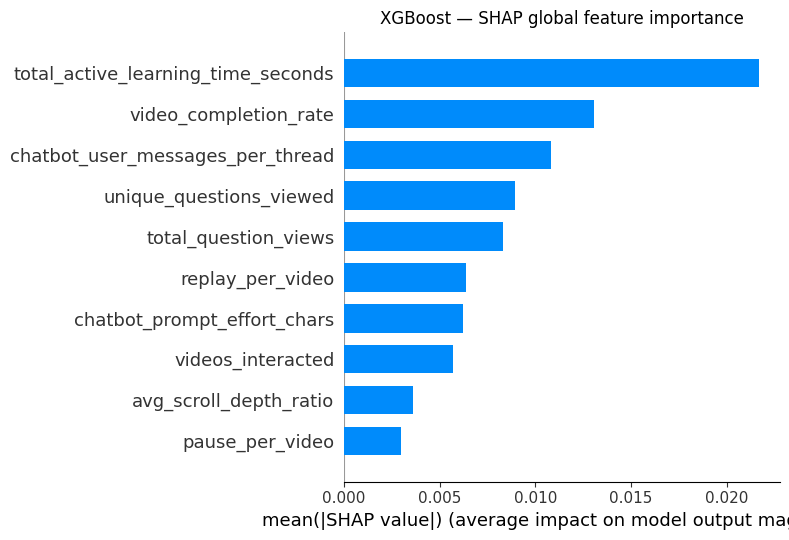

In [43]:
# ── SHAP bar plot (XGBoost) ──
shap.summary_plot(shap_values_xgb, X, plot_type="bar", show=False)
plt.title("XGBoost — SHAP global feature importance")
plt.tight_layout()
plt.show()


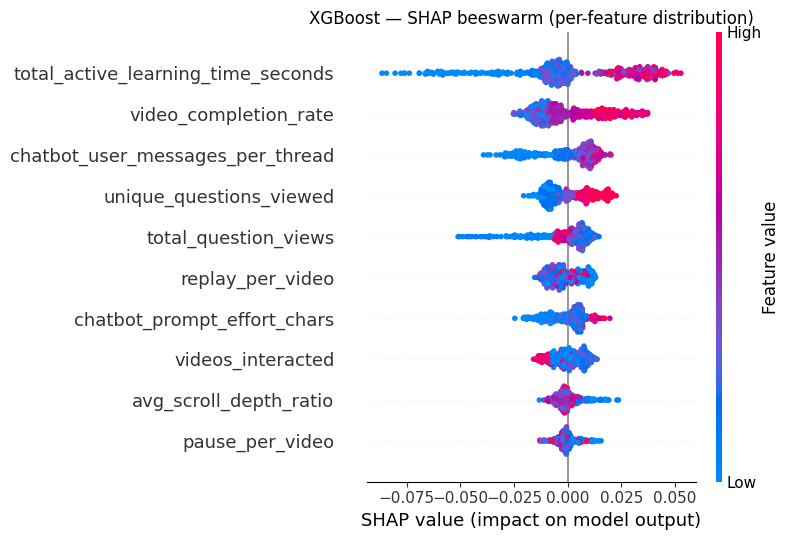

In [44]:
# ── SHAP beeswarm plot (XGBoost) — direction + magnitude per feature ──
shap.summary_plot(shap_values_xgb, X, show=False)
plt.title("XGBoost — SHAP beeswarm (per-feature distribution)")
plt.tight_layout()
plt.show()


XGBoost — SHAP importance aggregated by dimension:
      dimension  mean_abs_shap
  Content_Depth       0.031663
         Effort       0.021693
Practice_Review       0.017234
   Help_Seeking       0.017005


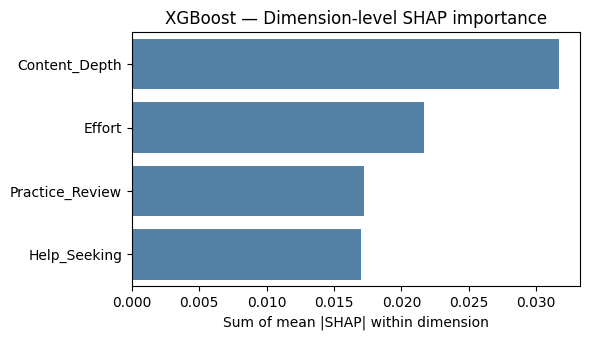

In [45]:
# ── Dimension-level SHAP importance (XGBoost) ──
dim_imp_xgb = (
    shap_imp_xgb.groupby("dimension")["mean_abs_shap"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
print("XGBoost — SHAP importance aggregated by dimension:")
print(dim_imp_xgb.to_string(index=False))

plt.figure(figsize=(6, 3.5))
sns.barplot(
    data=dim_imp_xgb,
    x="mean_abs_shap", y="dimension",
    color="steelblue",
)
plt.xlabel("Sum of mean |SHAP| within dimension")
plt.ylabel("")
plt.title("XGBoost — Dimension-level SHAP importance")
plt.tight_layout()
plt.show()


### Combined SHAP figure — importance (direction-coloured) + beeswarm

Replaces the separate bar and beeswarm plots with one figure (used as Figure 2 in the report). Features are grouped by dimension; **left** bars show global importance (mean $|\phi|$) coloured by the correlation between each feature's value and its SHAP value (green = raises score, red = lowers, pale = near-zero); **right** is the per-student beeswarm. Reuses `shap_values_xgb`, `X`, `shap_imp_xgb`, `FEATURE_COLS`.

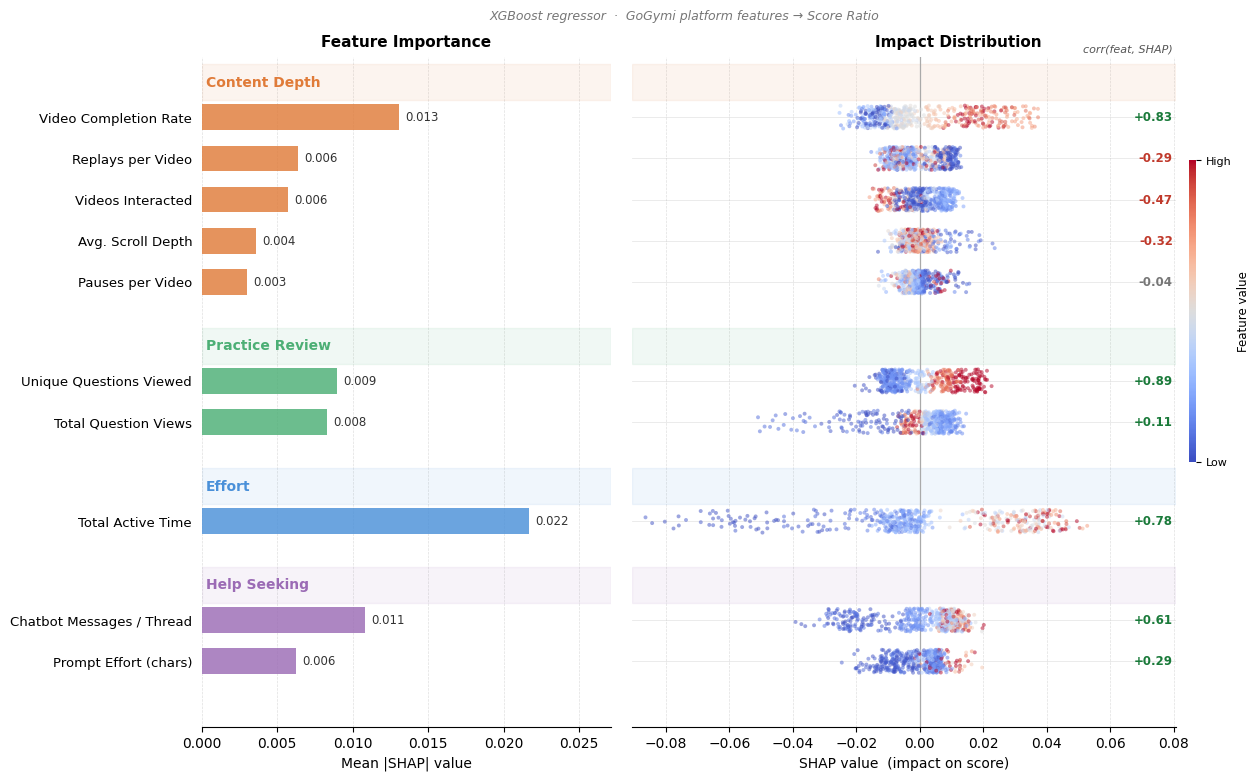

In [46]:
# ── Combined SHAP: feature importance (left, coloured by direction) + beeswarm (right) ──
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec

# inputs from the SHAP-XGBoost cells above
shap_imp_final    = shap_imp_xgb            # cols: feature, dimension, mean_abs_shap
X_final           = X
shap_values_final = shap_values_xgb
VAL = "mean_abs_shap"                       # importance column name

DISPLAY_NAMES = {
    "total_active_learning_time_seconds": "Total Active Time",
    "video_completion_rate":              "Video Completion Rate",
    "videos_interacted":                  "Videos Interacted",
    "pause_per_video":                    "Pauses per Video",
    "replay_per_video":                   "Replays per Video",
    "avg_scroll_depth_ratio":             "Avg. Scroll Depth",
    "chatbot_user_messages_per_thread":   "Chatbot Messages / Thread",
    "chatbot_prompt_effort_chars":        "Prompt Effort (chars)",
    "unique_questions_viewed":            "Unique Questions Viewed",
    "total_question_views":               "Total Question Views",
}
DIM_ORDER  = ["Content_Depth", "Practice_Review", "Effort", "Help_Seeking"]
DIM_LABELS = {"Content_Depth":"Content Depth","Practice_Review":"Practice Review",
              "Effort":"Effort","Help_Seeking":"Help Seeking"}
DIM_COLORS = {"Content_Depth":"#E07B39","Practice_Review":"#4CAF75",
              "Effort":"#4A90D9","Help_Seeking":"#9B6BB5"}
HEADER_H, GAP = 0.85, 0.55

# direction = correlation between each feature's raw values and its SHAP values
dir_corr = {}
for feat in FEATURE_COLS:
    j = list(X_final.columns).index(feat)
    dir_corr[feat] = float(np.corrcoef(X_final.iloc[:, j].values, shap_values_final[:, j])[0, 1])
bar_cmap = plt.get_cmap("RdYlGn")
cmax     = max(abs(v) for v in dir_corr.values())
bar_norm = mcolors.TwoSlopeNorm(vmin=-cmax, vcenter=0.0, vmax=cmax)

df_imp = shap_imp_final.copy()
df_imp["display"] = df_imp["feature"].map(DISPLAY_NAMES)

plot_rows, y_cursor = [], 0.0
for dim in DIM_ORDER:
    plot_rows.append({"kind":"header","label":DIM_LABELS[dim],"color":DIM_COLORS[dim],"y":y_cursor})
    y_cursor += HEADER_H
    sub = df_imp[df_imp["dimension"] == dim].sort_values(VAL, ascending=False)
    for _, row in sub.iterrows():
        plot_rows.append({"kind":"feature","feature":row["feature"],"label":row["display"],
                          "value":row[VAL],"color":DIM_COLORS[dim],"y":y_cursor})
        y_cursor += 1.0
    y_cursor += GAP

y_max  = y_cursor - GAP
val_max = shap_imp_final[VAL].max()
n_rows  = sum(1 for r in plot_rows if r["kind"] == "feature")

fig = plt.figure(figsize=(14, max(6.5, n_rows * 0.62 + 2.5)))
gs  = gridspec.GridSpec(1, 2, width_ratios=[1, 1.6], wspace=0.04)
ax_bar = fig.add_subplot(gs[0]); ax_bee = fig.add_subplot(gs[1], sharey=ax_bar)
cmap = plt.get_cmap("coolwarm"); rng = np.random.default_rng(42)
y_ticks, y_labels = [], []

for r in plot_rows:
    yp = y_max - r["y"]
    if r["kind"] == "header":
        for ax in (ax_bar, ax_bee):
            ax.axhspan(yp - HEADER_H*0.52, yp + HEADER_H*0.52, color=r["color"], alpha=0.08, zorder=1)
        ax_bar.text(0.01, yp, r["label"], transform=ax_bar.get_yaxis_transform(),
                    va="center", ha="left", fontsize=10, color=r["color"], fontweight="bold", zorder=3)
        y_ticks.append(yp); y_labels.append("")
    else:
        ax_bar.barh(yp, r["value"], height=0.62, color=r["color"], alpha=0.82, zorder=2)
        ax_bar.text(r["value"] + val_max*0.02, yp, f'{r["value"]:.3f}',
                    va="center", ha="left", fontsize=8.5, color="#333")
        fidx = list(X_final.columns).index(r["feature"])
        shap_v = shap_values_final[:, fidx]; feat_v = X_final.iloc[:, fidx].values
        lo, hi = np.nanpercentile(feat_v, 5), np.nanpercentile(feat_v, 95)
        norm = np.clip((feat_v - lo) / (hi - lo + 1e-9), 0, 1)
        ax_bee.scatter(shap_v, yp + rng.uniform(-0.28, 0.28, size=len(shap_v)),
                       c=cmap(norm), s=8, alpha=0.50, linewidths=0, zorder=2)
        ax_bee.axhline(yp, color="#e8e8e8", lw=0.6, zorder=0)
        # corr(feature, SHAP) printed beside the beeswarm row
        cc = dir_corr[r["feature"]]
        num_col = "#1a7a3a" if cc >= 0.08 else ("#c0392b" if cc <= -0.08 else "#777")
        ax_bee.text(0.995, yp, f"{cc:+.2f}", transform=ax_bee.get_yaxis_transform(),
                    va="center", ha="right", fontsize=8.5, color=num_col, fontweight="bold", zorder=4)
        y_ticks.append(yp); y_labels.append(r["label"])

ax_bar.set_yticks(y_ticks); ax_bar.set_yticklabels(y_labels, fontsize=9.5)
ax_bee.tick_params(labelleft=False); ax_bee.axvline(0, color="#aaa", lw=0.9, zorder=1)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=mcolors.Normalize(0, 1)); sm.set_array([])
cbar = fig.colorbar(sm, ax=ax_bee, aspect=40, pad=0.02, shrink=0.45, anchor=(0.0, 0.72))
cbar.set_ticks([0, 1]); cbar.set_ticklabels(["Low", "High"], fontsize=8)
cbar.set_label("Feature value", fontsize=8.5); cbar.outline.set_visible(False)

ax_bee.text(0.995, 1.005, "corr(feat, SHAP)", transform=ax_bee.transAxes,
            ha="right", va="bottom", fontsize=8, color="#555", style="italic")

ax_bar.set_xlabel("Mean |SHAP| value", fontsize=10)
ax_bar.set_title("Feature Importance", fontsize=11, fontweight="bold", pad=8)
ax_bee.set_xlabel("SHAP value  (impact on score)", fontsize=10)
ax_bee.set_title("Impact Distribution", fontsize=11, fontweight="bold", pad=8, x=0.6)
for ax in (ax_bar, ax_bee):
    ax.spines[["top","right","left"]].set_visible(False); ax.tick_params(left=False)
    ax.xaxis.grid(True, linestyle="--", linewidth=0.5, alpha=0.4, zorder=0)
    ax.set_axisbelow(True); ax.set_ylim(-0.6, y_max + 0.6)
ax_bar.set_xlim(left=0, right=val_max * 1.25)
_smin, _smax = float(shap_values_final.min()), float(shap_values_final.max()); _pad = _smax - _smin
ax_bee.set_xlim(_smin - 0.03*_pad, _smax + 0.20*_pad)
fig.text(0.47, 0.92, "XGBoost regressor  ·  GoGymi platform features → Score Ratio",
         ha="center", va="bottom", fontsize=9, color="#777", style="italic")
plt.tight_layout()
fig.savefig("M7_MLBD_Final_Report/rq2_shap.png", bbox_inches="tight", dpi=1000)
plt.show()


### SHAP — Random Forest robustness check
Strong agreement between models due to high Spearman rank correlation $\rho=0.98$, $p=1.46*10^{-6}$: conclusions are robust across models.

In [47]:
# ── Random Forest regressor with 5-fold CV ──

rf_reg = RandomForestRegressor(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

r2_rf   =  cross_val_score(rf_reg, X, y, cv=kf, scoring="r2", n_jobs=-1)

print("Random Forest — 5-fold CV on average_score_ratio")
print(f"  R2   : {r2_rf.mean():+.4f} ± {r2_rf.std():.4f}")

# Fit on full data for SHAP analysis
rf_reg.fit(X, y)


Random Forest — 5-fold CV on average_score_ratio
  R2   : +0.0494 ± 0.0454


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [48]:
# ── TreeSHAP on Random Forest regressor — φ values in score-ratio units ──

explainer_rf = shap.TreeExplainer(rf_reg)
shap_values_rf = np.asarray(explainer_rf.shap_values(X))
assert shap_values_rf.ndim == 2, f"Unexpected SHAP shape: {shap_values_rf.shape}"

mean_abs_shap_rf = np.abs(shap_values_rf).mean(axis=0).ravel()
shap_imp_rf = (
    pd.DataFrame({
        "feature": FEATURE_COLS,
        "dimension": [FEATURE_TO_DIM[f] for f in FEATURE_COLS],
        "mean_abs_shap": mean_abs_shap_rf,
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)
print("Random Forest — Global SHAP importance (mean |phi_f|, score-ratio units):")
print(shap_imp_rf.to_string(index=False))


Random Forest — Global SHAP importance (mean |phi_f|, score-ratio units):
                           feature       dimension  mean_abs_shap
total_active_learning_time_seconds          Effort       0.028426
             video_completion_rate   Content_Depth       0.014858
  chatbot_user_messages_per_thread    Help_Seeking       0.013423
              total_question_views Practice_Review       0.011915
           unique_questions_viewed Practice_Review       0.011393
       chatbot_prompt_effort_chars    Help_Seeking       0.009371
                  replay_per_video   Content_Depth       0.009100
                 videos_interacted   Content_Depth       0.007820
            avg_scroll_depth_ratio   Content_Depth       0.007095
                   pause_per_video   Content_Depth       0.005780


In [49]:
# ── Robustness check: rank agreement between XGBoost & Random Forest ──
from scipy.stats import spearmanr

ranks_xgb = shap_imp_xgb.set_index("feature").rank(ascending=False)["mean_abs_shap"]
ranks_rf  = shap_imp_rf.set_index("feature").rank(ascending=False)["mean_abs_shap"]

compare = pd.DataFrame({
    "rank_xgb": ranks_xgb,
    "rank_rf":  ranks_rf,
}).loc[FEATURE_COLS]

rho, p = spearmanr(compare["rank_xgb"], compare["rank_rf"])
print("Spearman rank correlation between XGBoost and RF SHAP importance:")
print(f"  rho = {rho:.4f}   p = {p:.4e}")
if rho > 0.7:
    print("  → Strong agreement: conclusions are robust across models.")
elif rho > 0.4:
    print("  → Moderate agreement.")
else:
    print("  → Weak agreement: interpret cautiously.")

print("\nFeature rank comparison (1 = most important):")
print(compare.sort_values("rank_xgb").to_string())


Spearman rank correlation between XGBoost and RF SHAP importance:
  rho = 0.9758   p = 1.4675e-06
  → Strong agreement: conclusions are robust across models.

Feature rank comparison (1 = most important):
                                    rank_xgb  rank_rf
feature                                              
total_active_learning_time_seconds       1.0      1.0
video_completion_rate                    2.0      2.0
chatbot_user_messages_per_thread         3.0      3.0
unique_questions_viewed                  4.0      5.0
total_question_views                     5.0      4.0
replay_per_video                         6.0      7.0
chatbot_prompt_effort_chars              7.0      6.0
videos_interacted                        8.0      8.0
avg_scroll_depth_ratio                   9.0      9.0
pause_per_video                         10.0     10.0


### LIME — Spearman rank-order agreement with SHAP (XGBoost)

We validate the SHAP attributions against a second, independent explainer. Using **LIME** on the *same* XGBoost regressor and the same 10 VIF-screened features, we explain **every** student locally and compare its feature-importance vector to SHAP's via **Spearman's rank-order correlation** ($\rho$) over the 10 features.

- **Local agreement** — $\rho$ is computed per student between $|\phi^{\text{SHAP}}|$ and $|w^{\text{LIME}}|$, then summarised as a distribution across all 531 students.

**Results:** Across all 531 students, the per-student Spearman $\rho$ between $|\phi^{\text{SHAP}}|$ and $|w^{\text{LIME}}|$ has a **mean of 0.644** (median 0.685, std 0.198). Critically, **100% of students show positive rank agreement** ($\rho > 0$), indicating that LIME and SHAP consistently agree on the relative ordering of feature importances at the individual level. This cross-explainer consistency confirms that the identified feature drivers are not an artefact of the SHAP method alone.

In [50]:
# ── SHAP vs LIME on XGBoost — per-student Spearman rank-order correlation ──
import lime, lime.lime_tabular
from scipy.stats import spearmanr

# LIME explainer on the same XGBoost model / feature set (regression mode)
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X.values, feature_names=FEATURE_COLS,
    mode="regression", discretize_continuous=True, random_state=RANDOM_STATE,
)

def _lime_vec(exp):
    """Map LIME's (feature_string, weight) tuples back to the raw feature order."""
    w = {f: 0.0 for f in FEATURE_COLS}
    for lab, val in exp.as_list():
        for f in FEATURE_COLS:
            if f in lab:
                w[f] = val; break
    return np.array([w[f] for f in FEATURE_COLS])

# For each student: |SHAP| vs |LIME| local importance, then Spearman rho over the 10 features
n = len(X)
rhos = np.empty(n)
lime_abs_mat = np.zeros((n, len(FEATURE_COLS)))  # per-student |LIME|, reused for JSD
for i in range(n):
    exp = lime_explainer.explain_instance(
        X.iloc[i].values, xgb_reg.predict, num_features=len(FEATURE_COLS))
    lw = np.abs(_lime_vec(exp))
    lime_abs_mat[i] = lw
    rhos[i] = spearmanr(np.abs(shap_values_xgb[i]), lw).correlation

rhos = rhos[~np.isnan(rhos)]

print(f"Per-student Spearman rho (|SHAP| vs |LIME|) across {len(rhos)} students:")
print(f"  mean   = {rhos.mean():.3f}")
print(f"  median = {np.median(rhos):.3f}")
print(f"  std    = {rhos.std():.3f}")
print(f"  share with rho > 0 : {(rhos > 0).mean():.1%}")

Per-student Spearman rho (|SHAP| vs |LIME|) across 531 students:
  mean   = 0.644
  median = 0.685
  std    = 0.198
  share with rho > 0 : 100.0%


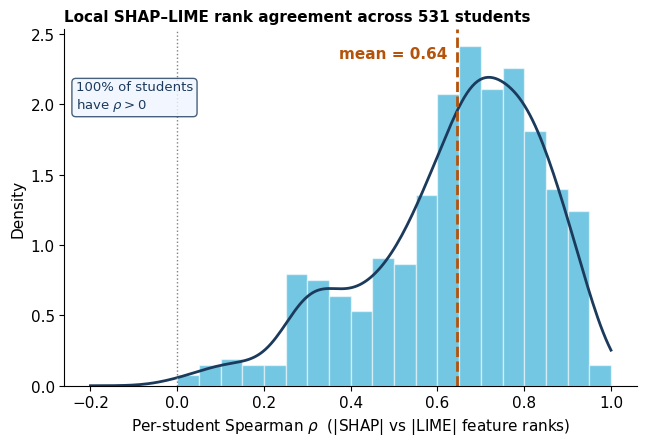

In [51]:
# ── Diagram: SHAP–LIME per-student Spearman rank-order agreement ──
from scipy.stats import gaussian_kde
NAVY, TEAL, AMBER = "#1B3A5C", "#0099cc", "#B45309"

plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False})
fig, ax1 = plt.subplots(figsize=(6.6, 4.6))

ax1.hist(rhos, bins=24, range=(-0.2,1.0), color=TEAL, alpha=0.55, edgecolor="white", density=True)
xs = np.linspace(-0.2,1.0,200); ax1.plot(xs, gaussian_kde(rhos)(xs), color=NAVY, lw=2)
m = rhos.mean(); ax1.axvline(m, color=AMBER, lw=2, ls="--")
ax1.text(m-0.02, ax1.get_ylim()[1]*0.92, f"mean = {m:.2f}", color=AMBER, ha="right", fontweight="bold")
ax1.axvline(0, color="grey", lw=1, ls=":")
ax1.set_xlabel(r"Per-student Spearman $\rho$  (|SHAP| vs |LIME| feature ranks)")
ax1.set_ylabel("Density")
ax1.set_title("Local SHAP–LIME rank agreement across %d students" % len(rhos),
              fontweight="bold", fontsize=11, loc="left")
ax1.text(0.02, 0.78, f"{(rhos>0).mean()*100:.0f}% of students\n"r"have $\rho>0$", transform=ax1.transAxes,
         fontsize=9.5, color=NAVY, bbox=dict(boxstyle="round", fc="#EFF6FF", ec=NAVY, alpha=0.8))
fig.tight_layout()
fig.savefig("M7_MLBD_Final_Report/rq2_robustness_sprearman.png", bbox_inches="tight", dpi=1000)
plt.show()

### LIME vs SHAP — Jensen–Shannon distance

Spearman compares the *ranking* of features; to also compare the **exact normalised importance values**, we treat each student's importance vector as a probability distribution (L1-normalised to sum to 1) and measure the **Jensen–Shannon distance** between the SHAP and LIME distributions. JSD is bounded in $[0,1]$: 0 means the two explainers distribute importance identically, 1 means maximal disagreement.

**Results:** The per-student Jensen–Shannon distance has a **mean of 0.272** (median 0.266, std 0.075), well below the midpoint of the $[0,1]$ scale. **99.8% of students fall below JSD = 0.5**, confirming that not only do SHAP and LIME agree on feature rankings, they also assign quantitatively similar normalised importance weights. Together with the Spearman results, this dual-metric agreement — following the protocol of Swamy et al. — provides strong evidence that the driver ranking is an artefact of neither the learner architecture nor the choice of explainer.

Per-student Jensen-Shannon distance (SHAP vs LIME) across 531 students:
  mean   = 0.272
  median = 0.266
  std    = 0.075
  share below 0.5 : 99.8%


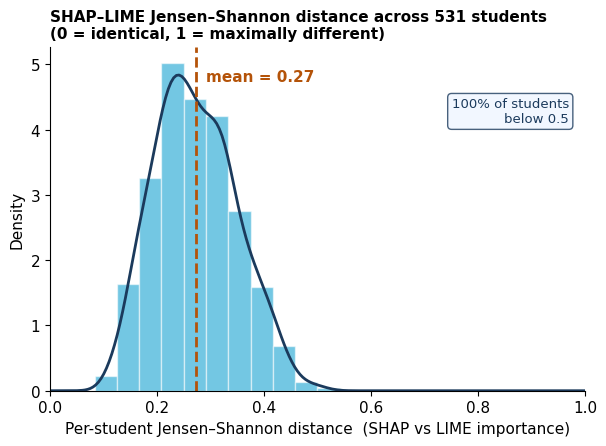

In [52]:
# ── SHAP vs LIME — per-student Jensen–Shannon distance ──
from scipy.spatial.distance import jensenshannon

eps = 1e-12
shap_abs_mat = np.abs(shap_values_xgb)
jsd = np.array([
    jensenshannon(shap_abs_mat[i] / (shap_abs_mat[i].sum() + eps),
                  lime_abs_mat[i] / (lime_abs_mat[i].sum() + eps), base=2)
    for i in range(len(X))
])
jsd = jsd[~np.isnan(jsd)]

print(f"Per-student Jensen-Shannon distance (SHAP vs LIME) across {len(jsd)} students:")
print(f"  mean   = {jsd.mean():.3f}")
print(f"  median = {np.median(jsd):.3f}")
print(f"  std    = {jsd.std():.3f}")
print(f"  share below 0.5 : {(jsd < 0.5).mean():.1%}")

# ── Histogram ──
from scipy.stats import gaussian_kde
NAVY, TEAL, AMBER = "#1B3A5C", "#0099cc", "#B45309"
plt.rcParams.update({"font.size":11,"axes.spines.top":False,"axes.spines.right":False})

fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.hist(jsd, bins=24, range=(0,1), color=TEAL, alpha=0.55, edgecolor="white", density=True)
xs = np.linspace(0,1,200); ax.plot(xs, gaussian_kde(jsd)(xs), color=NAVY, lw=2)
m = jsd.mean(); ax.axvline(m, color=AMBER, lw=2, ls="--")
ax.text(m+0.02, ax.get_ylim()[1]*0.9, f"mean = {m:.2f}", color=AMBER, fontweight="bold")
ax.set_xlabel("Per-student Jensen–Shannon distance  (SHAP vs LIME importance)")
ax.set_ylabel("Density"); ax.set_xlim(0,1)
ax.set_title("SHAP–LIME Jensen–Shannon distance across %d students\n(0 = identical, 1 = maximally different)" % len(jsd),
             fontweight="bold", fontsize=11, loc="left")
ax.text(0.97, 0.78, f"{(jsd<0.5).mean()*100:.0f}% of students\nbelow 0.5", transform=ax.transAxes, ha="right",
        fontsize=9.5, color=NAVY, bbox=dict(boxstyle="round", fc="#EFF6FF", ec=NAVY, alpha=0.8))
fig.savefig("M7_MLBD_Final_Report/rq2_robustness_jensen.png", bbox_inches="tight", dpi=1000)
fig.tight_layout()
plt.show()